# Fluorescence crosstalk versus 397 nm and 866 nm saturation

Steady-state, simultaneous 397/866 nm illumination of $^{40}\mathrm{Ca}^{+}$, using the **effective three-level rate model in the supplied manuscript section**. This notebook estimates saturation from the supplied powers and Gaussian beam sizes, then sweeps both saturation parameters. All curves are model predictions, not measured fluorescence.

**Inputs:** 397 nm: 15 µW, 40 × 200 µm **diameters**, −20 MHz detuning; 866 nm: 50 µW, 0.94 × 6 µm **radii**, on resonance. Sizes are assumed to be **1/e² intensity** sizes. The 866 nm input power has **12 dB loss**, so 50 µW becomes **3.15 µW at the ion plane**; 397 nm remains 15 µW at the ions. Power-sweep axes refer to input power before this loss. The addressed ion is initially at each beam's center. Transmission, local overlap, and coupling strengths are editable below.

Optical leakage $c=I_{866,n}/I_{866,t}$ is independent of saturation: current setting **−20 dB**. The supplied section’s −25 dB example is retained only as a numerical model check. The measured 830 nm image is **not** silently treated as an 866 nm calibration. The neighboring-ion spacing is 5 µm; the main analysis assumes equal 397 nm excitation, with a separate check of the free-space beam's spatial variation.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

plt.rcParams.update({
    'font.family': 'Arial', 'font.size': 18,
    'axes.labelsize': 18, 'axes.titlesize': 18,
    'xtick.labelsize': 18, 'ytick.labelsize': 18,
    'legend.fontsize': 13, 'svg.fonttype': 'none',
    'svg.image_inline': True, 'figure.facecolor': 'white',
})
HERE = Path.cwd()
PAPER_DIR = HERE if HERE.name == 'Gen_1_Paper' else HERE / 'Gen_1_Paper'
OUTPUT_DIR = PAPER_DIR / 'fluorescence_crosstalk_results_ca'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# All powers are BEFORE the editable transmission factors below.
POWER_397_UW = 15.0
POWER_866_UW = 50.0
DIAMETERS_397_UM = np.array([40.0, 200.0])  # 1/e^2 intensity diameters
RADII_866_UM = np.array([0.94, 6.0])         # 1/e^2 intensity radii
TRANSMISSION_397 = 1.0                      # power fraction reaching the ion plane
LOSS_866_DB = 12.0
TRANSMISSION_866 = 10**(-LOSS_866_DB/10)    # 12 dB loss: 50 uW input -> 3.15 uW at ions
LOCAL_OVERLAP_397 = 1.0                     # local intensity / Gaussian peak
LOCAL_OVERLAP_866 = 1.0
DETUNING_397_MHZ = -20.0                    # ordinary frequency, not rad/s
DETUNING_866_MHZ = 0.0

# Effective squared dipole strength relative to the full decay branch.
# 1/3 is an illustrative single pi-transition choice on BOTH legs.
# This is an ASSUMPTION, not a measured polarization or multilevel calibration.
DIPOLE_FRACTION_397 = 1/3
DIPOLE_FRACTION_866 = 1/3

BRANCH_D = 0.06435
LIFETIME_P_NS = 7.098
LAMBDA_397_NM = 397.0
LAMBDA_866_NM = 866.0
OPTICAL_CROSSTALK_DB = -20.0
TARGET_FLUORESCENCE_DB = -5.0
ION_SEPARATION_UM = 5.0

# Scans are physical parameter sweeps, not uncertainty intervals.
S397_TILDE_LIMITS = (1e-3, 1e3)
S866_TILDE_LIMITS = (1e-5, 1e5)
POWER_866_SCAN_LIMITS_UW = (1e-5, 500.0)
COOLING_POWER_FACTORS = (0.1, 1.0, 10.0)
REPUMP_POWER_FACTORS = (0.0001, 0.001, 0.01, 1.0)

## Saturation convention and conversion from power

For $I(x,y)=I_0\exp[-2(x^2/w_x^2+y^2/w_y^2)]$, $I_0=2P/(\pi w_xw_y)$. The 397 nm radii are therefore **20 × 100 µm**, while the 866 nm radii are **0.94 × 6 µm**. Here $P$ is the power reaching the ion plane: $P_{866}=P_{866,\mathrm{in}}10^{-L_{866}/10}$, with $L_{866}=12$ dB.

Use the manuscript convention
\[
s_j=\frac{2\Omega_j^2}{\Gamma^2},\quad
\widetilde{s}_j=\frac{s_j}{1+(2\Delta_j/\Gamma)^2},\quad
W_j=\frac{\Gamma}{2}\widetilde{s}_j,\qquad \Gamma=1/\tau_P.
\]
Here $\Delta_j=2\pi\delta\nu_j$. The **total P-state decay rate** determines the linewidth on both legs; the small 866 nm branching rate is not substituted for that linewidth.

To make the power conversion explicit, let $B_{397}=1-b$, $B_{866}=b$, and let $\chi_j$ be the fraction of that branch's squared dipole strength assigned to the effective driven transition:
\[
|d_{\mathrm{eff},j}|^2=\chi_j\frac{3\pi\epsilon_0\hbar c^3 B_j\Gamma}{\omega_j^3},\qquad
I_{\mathrm{sat},j}=\frac{\pi h c\Gamma}{3\lambda_j^3 B_j\chi_j},\qquad
s_j=I_j/I_{\mathrm{sat},j}.
\]
This follows from the dipole spontaneous-emission and Rabi-frequency relations; it includes **both the branch strength and the total linewidth**. There is no polarization-independent saturation intensity for the full Zeeman manifold. The default $\chi_{397}=\chi_{866}=1/3$ is an illustrative π-component assumption; optical pumping and the actual polarization can change the effective couplings. A sensitivity table below also evaluates other choices. The rate model still aggregates each manifold into one state.

In [2]:
H = 6.62607015e-34
C = 299792458.0
GAMMA = 1.0 / (LIFETIME_P_NS * 1e-9)
LINEWIDTH_MHZ = GAMMA / (2*np.pi*1e6)
BRANCH_S = 1.0 - BRANCH_D


def gaussian_peak_intensity(power_uw, radii_um):
    radii = np.asarray(radii_um, dtype=float)
    power = np.asarray(power_uw, dtype=float)
    if radii.shape != (2,) or np.any(radii <= 0) or not np.isfinite(radii).all():
        raise ValueError('Supply two finite positive 1/e^2 radii')
    if np.any(power < 0) or not np.isfinite(power).all():
        raise ValueError('Power must be finite and nonnegative')
    return 2*power*1e-6 / (np.pi*np.prod(radii*1e-6))  # W/m^2


def saturation_intensity(wavelength_nm, branch, dipole_fraction):
    if not (wavelength_nm > 0 and 0 < branch <= 1 and 0 < dipole_fraction <= 1):
        raise ValueError('Require positive wavelength and branch/coupling fractions in (0, 1]')
    return np.pi*H*C*GAMMA / (3*(wavelength_nm*1e-9)**3*branch*dipole_fraction)


def detuning_factor(detuning_mhz):
    return 1 + (2*np.asarray(detuning_mhz)/LINEWIDTH_MHZ)**2


def excited_population(s397_tilde, s866_tilde):
    """Steady-state p_P in the supplied incoherent three-level rate model."""
    sc, sr = np.broadcast_arrays(np.asarray(s397_tilde, float), np.asarray(s866_tilde, float))
    if np.any(sc < 0) or np.any(sr < 0) or not np.isfinite(sc).all() or not np.isfinite(sr).all():
        raise ValueError('Detuning-corrected saturation parameters must be finite and nonnegative')
    with np.errstate(divide='ignore', invalid='ignore'):
        p = 1/(3 + 2*BRANCH_S/sc + 2*BRANCH_D/sr)
    return np.where((sc == 0) | (sr == 0), 0.0, p)


def effective_u(s397_tilde, s866_tilde):
    sc, sr = np.broadcast_arrays(np.asarray(s397_tilde, float), np.asarray(s866_tilde, float))
    if np.any(sc <= 0) or np.any(sr < 0):
        raise ValueError('u requires positive 397 excitation and nonnegative repump')
    return (3 + 2*BRANCH_S/sc)*sr/(2*BRANCH_D)


def fluorescence_ratio(optical_ratio, s397_tilde, s866_tilde, cooling_neighbor_ratio=1.0):
    """Neighbor / target fluorescence; allows a different 397 intensity at the neighbor."""
    leak, sc, sr, a = np.broadcast_arrays(
        np.asarray(optical_ratio, float), np.asarray(s397_tilde, float),
        np.asarray(s866_tilde, float), np.asarray(cooling_neighbor_ratio, float))
    if np.any(leak < 0) or np.any(a < 0):
        raise ValueError('Local intensity ratios must be nonnegative')
    target = excited_population(sc, sr)
    neighbor = excited_population(a*sc, leak*sr)
    with np.errstate(divide='ignore', invalid='ignore'):
        return np.where(target > 0, neighbor/target, np.nan)


def to_db(ratio):
    with np.errstate(divide='ignore', invalid='ignore'):
        return 10*np.log10(np.asarray(ratio, float))


for fraction in (TRANSMISSION_397, TRANSMISSION_866, LOCAL_OVERLAP_397, LOCAL_OVERLAP_866):
    if not 0 < fraction <= 1:
        raise ValueError('Transmission and local-overlap factors must be in (0, 1]')
if POWER_397_UW <= 0 or POWER_866_UW <= 0 or OPTICAL_CROSSTALK_DB >= 0:
    raise ValueError('Require positive powers and negative optical-crosstalk dB')
RADII_397_UM = DIAMETERS_397_UM / 2
I397 = gaussian_peak_intensity(POWER_397_UW*TRANSMISSION_397, RADII_397_UM)*LOCAL_OVERLAP_397
I866 = gaussian_peak_intensity(POWER_866_UW*TRANSMISSION_866, RADII_866_UM)*LOCAL_OVERLAP_866
ISAT397 = saturation_intensity(LAMBDA_397_NM, BRANCH_S, DIPOLE_FRACTION_397)
ISAT866 = saturation_intensity(LAMBDA_866_NM, BRANCH_D, DIPOLE_FRACTION_866)
S397 = I397/ISAT397
S866 = I866/ISAT866
SC = S397/detuning_factor(DETUNING_397_MHZ)
SR = S866/detuning_factor(DETUNING_866_MHZ)
LEAK = 10**(OPTICAL_CROSSTALK_DB/10)
U = float(effective_u(SC, SR))
NOMINAL_RATIO = float(fluorescence_ratio(LEAK, SC, SR))

saturation_table = pd.DataFrame([
    dict(wavelength_nm=397, power_uw=POWER_397_UW, power_at_ions_uw=POWER_397_UW*TRANSMISSION_397, transmission=TRANSMISSION_397, radius_1_um=RADII_397_UM[0], radius_2_um=RADII_397_UM[1],
         local_intensity_w_m2=I397, isat_w_m2=ISAT397, detuning_mhz=DETUNING_397_MHZ,
         dipole_fraction=DIPOLE_FRACTION_397, s=S397, s_tilde=SC,
         rabi_over_2pi_mhz=LINEWIDTH_MHZ*np.sqrt(S397/2)),
    dict(wavelength_nm=866, power_uw=POWER_866_UW, power_at_ions_uw=POWER_866_UW*TRANSMISSION_866, transmission=TRANSMISSION_866, radius_1_um=RADII_866_UM[0], radius_2_um=RADII_866_UM[1],
         local_intensity_w_m2=I866, isat_w_m2=ISAT866, detuning_mhz=DETUNING_866_MHZ,
         dipole_fraction=DIPOLE_FRACTION_866, s=S866, s_tilde=SR,
         rabi_over_2pi_mhz=LINEWIDTH_MHZ*np.sqrt(S866/2)),
])
display(saturation_table.round(5))
print(f'Total natural linewidth Γ/(2π) = {LINEWIDTH_MHZ:.3f} MHz')
print(f'Effective target repump parameter u = {U:.4g}; neighbor c*u = {LEAK*U:.4g}')
print(f'Optical leakage: {OPTICAL_CROSSTALK_DB:g} dB ({100*LEAK:.4f}%)')
print(f'Predicted fluorescence ratio: {to_db(NOMINAL_RATIO):.4f} dB ({100*NOMINAL_RATIO:.4f}%)')
saturation_table.to_csv(OUTPUT_DIR/'operating_point_saturation.csv', index=False)

 wavelength_nm  power_uw  power_at_ions_uw  transmission  radius_1_um  radius_2_um  local_intensity_w_m2  isat_w_m2  detuning_mhz  dipole_fraction         s   s_tilde  rabi_over_2pi_mhz
           397      15.0          15.00000        1.0000        20.00        100.0            4774.64829 1501.77776         -20.0          0.33333   3.17933   0.76017           28.27073
           866      50.0           3.15479        0.0631         0.94          6.0          356099.22076 2103.72217           0.0          0.33333 169.27103 169.27103          206.28158
Total natural linewidth Γ/(2π) = 22.423 MHz
Effective target repump parameter u = 7183; neighbor c*u = 71.83
Optical leakage: -20 dB (1.0000%)
Predicted fluorescence ratio: -0.0594 dB (98.6407%)


,wavelength_nm,power_uw,power_at_ions_uw,transmission,radius_1_um,radius_2_um,local_intensity_w_m2,isat_w_m2,detuning_mhz,dipole_fraction,s,s_tilde,rabi_over_2pi_mhz
0,397,15.0,15.00000,1.0000,20.00,100.0,4774.64829,1501.77776,-20.0,0.33333,3.17933,0.76017,28.27073
1,866,50.0,3.15479,0.0631,0.94,6.0,356099.22076,2103.72217,0.0,0.33333,169.27103,169.27103,206.28158


## Fluorescence response

The supplied model gives
\[
p_P=\left[3+\frac{2(1-b)}{\widetilde{s}_{397}}+\frac{2b}{\widetilde{s}_{866}}\right]^{-1},\qquad
F=\eta(1-b)\Gamma p_P.
\]
With equal 397 nm excitation at both ions,
\[
u=\frac{3+2(1-b)/\widetilde{s}_{397}}{2b}\widetilde{s}_{866,t},\qquad
r_F=\frac{F_n}{F_t}=\frac{c(1+u)}{1+cu}.
\]
**Both lasers affect the measured ratio.** Increasing 866 nm power raises $u$ and washes out fluorescence contrast. At fixed 866 nm excitation, reducing 397 nm excitation also raises $u$: the fluorescence plateau becomes lower, so a weaker repump can saturate the cycle. This can increase the *ratio* even though the absolute fluorescence decreases. The ratio is background-subtracted and detection efficiencies are assumed corrected. Use $10\log_{10}$ for both intensity and fluorescence ratios.

In [3]:
# Independent checks: solve the original population equations, then check the ratio formula.
for test_sc, test_sr in ((1e-3, 1e-4), (0.7, 3.8), (SC, SR), (100., 1e4)):
    wc, wr = test_sc/2, test_sr/2  # rates in units of Γ; state order S, P, D
    matrix = np.array([[-wc, wc+BRANCH_S, 0], [0, wr+BRANCH_D, -wr], [1, 1, 1]])
    populations = np.linalg.solve(matrix, np.array([0., 0., 1.]))
    np.testing.assert_allclose(populations[1], excited_population(test_sc, test_sr), rtol=1e-11)
    u_test = effective_u(test_sc, test_sr)
    np.testing.assert_allclose(fluorescence_ratio(LEAK, test_sc, test_sr),
                              LEAK*(1+u_test)/(1+LEAK*u_test), rtol=1e-12)
    assert populations.min() >= 0
np.testing.assert_allclose(fluorescence_ratio(LEAK, SC, 1e-12), LEAK, rtol=1e-8)
np.testing.assert_allclose(fluorescence_ratio(LEAK, SC, 1e12), 1., rtol=1e-8)
assert excited_population(0., SR) == 0 and excited_population(SC, 0.) == 0
assert np.isnan(fluorescence_ratio(LEAK, SC, 0.))  # 0/0 fluorescence is undefined
assert fluorescence_ratio(0., SC, SR) == 0.
# Reproduce the manuscript's illustrative -25 dB optical -> -5 dB fluorescence example.
example_c, example_rf = 10**(-25/10), 10**(-5/10)
example_u = (example_rf-example_c)/(example_c*(1-example_rf))
np.testing.assert_allclose(example_u, 144.78505426185217, rtol=1e-8)
print(f'Population-equation and limiting-case checks passed; manuscript example u = {example_u:.3f}.')

Population-equation and limiting-case checks passed; manuscript example u = 144.785.


<Figure size 900x650 with 2 Axes>


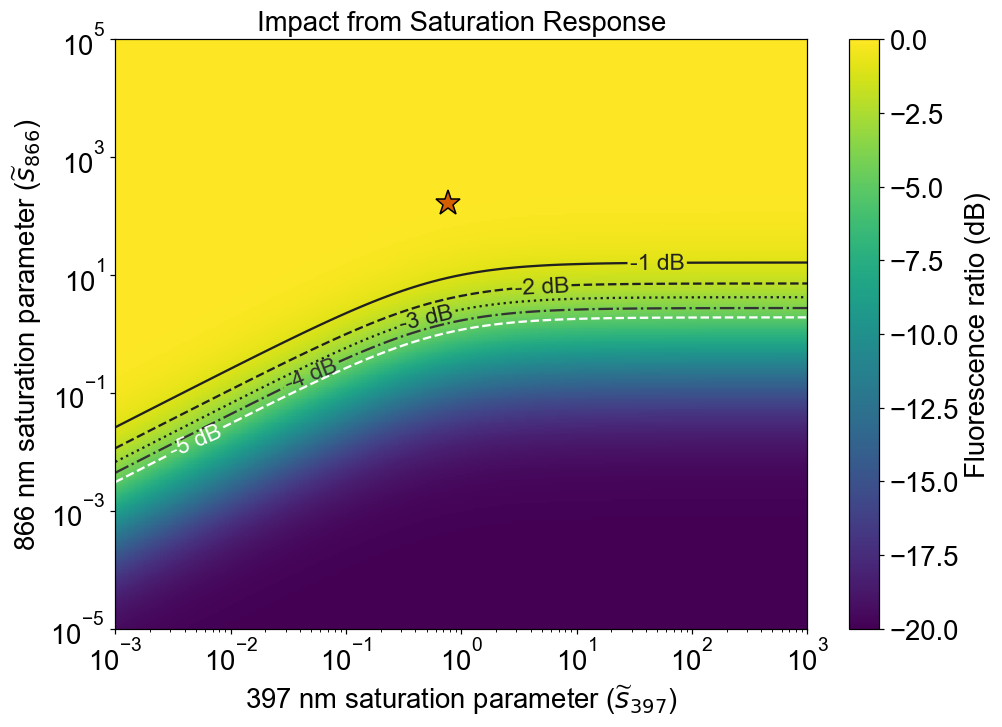

In [4]:
s397_axis = np.geomspace(*S397_TILDE_LIMITS, 301)
s866_axis = np.geomspace(*S866_TILDE_LIMITS, 321)
SC_GRID, SR_GRID = np.meshgrid(s397_axis, s866_axis)
ratio_grid_db = to_db(fluorescence_ratio(LEAK, SC_GRID, SR_GRID))
fig_map, ax = plt.subplots(figsize=(9, 6.5), constrained_layout=True)
mesh = ax.pcolormesh(s397_axis, s866_axis, ratio_grid_db, shading='auto',
                     cmap='viridis', vmin=OPTICAL_CROSSTALK_DB, vmax=0, rasterized=True)
# Set logarithmic scales before label placement so inline gaps use the final geometry.
ax.set_xscale('log')
ax.set_yscale('log')
CONTOUR_LEVELS_DB = [-5.0, -4.0, -3.0, -2.0, -1.0]
contour = ax.contour(SC_GRID, SR_GRID, ratio_grid_db, levels=CONTOUR_LEVELS_DB,
                     colors=['white', '#333333', '#202020', '#202020', '#202020'],
                     linestyles=['--', '-.', ':', '--', '-'], linewidths=1.5)
# Stagger labels horizontally so closely spaced contours remain readable.
label_sc_values = np.geomspace(S397_TILDE_LIMITS[0]*5, S397_TILDE_LIMITS[1]/20,
                               len(CONTOUR_LEVELS_DB))
label_positions = []
for level, label_sc in zip(CONTOUR_LEVELS_DB, label_sc_values):
    rf = 10**(level/10)
    u_level = (rf-LEAK)/(LEAK*(1-rf))
    label_positions.append((label_sc, u_level*2*BRANCH_D/(3+2*BRANCH_S/label_sc)))
ax.clabel(contour, fmt={level: f'{level:g} dB' for level in CONTOUR_LEVELS_DB},
          fontsize=15, manual=label_positions, inline=True, inline_spacing=5)
ax.plot(SC, SR, '*', color='#D55E00', markeredgecolor='black', markersize=17)
ax.set(xscale='log', yscale='log', xlim=S397_TILDE_LIMITS, ylim=S866_TILDE_LIMITS,
       xlabel=r'397 nm saturation parameter ($\widetilde{s}_{397}$)',
       ylabel=r'866 nm saturation parameter ($\widetilde{s}_{866}$)',
       title='Impact from Saturation Response')
cb = fig_map.colorbar(mesh, ax=ax, pad=.03)
cb.set_label('Fluorescence ratio (dB)')
display(fig_map)
fig_map.savefig(OUTPUT_DIR/'fluorescence_crosstalk_s397_s866.svg', bbox_inches='tight')
plt.close(fig_map)
pd.DataFrame({'s397_tilde': SC_GRID.ravel(), 's866_tilde': SR_GRID.ravel(),
              'fluorescence_ratio_db': ratio_grid_db.ravel()}).to_csv(
    OUTPUT_DIR/'fluorescence_crosstalk_s397_s866.csv', index=False)

<Figure size 1550x600 with 2 Axes>


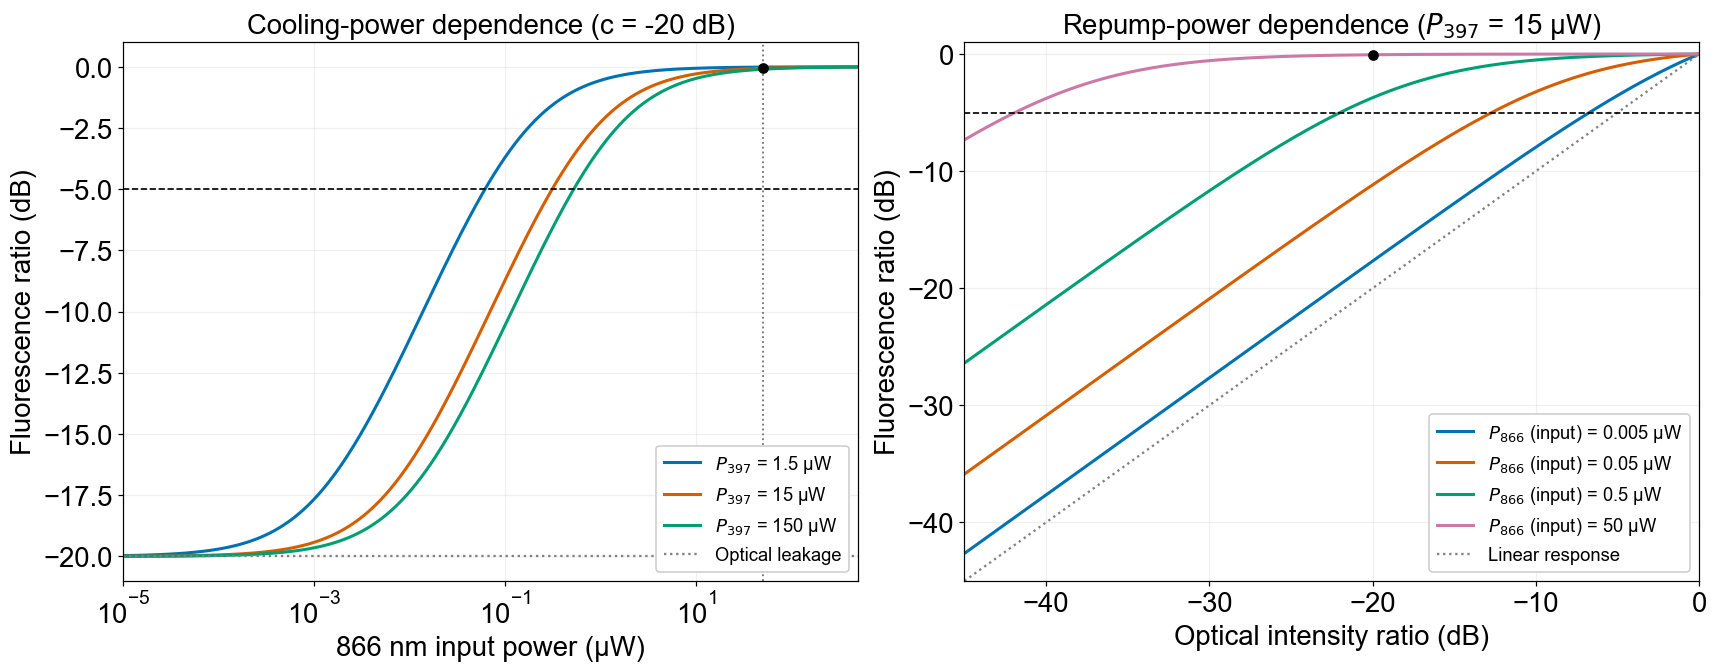

In [5]:
power866_axis = np.geomspace(*POWER_866_SCAN_LIMITS_UW, 601)
optical_db_axis = np.linspace(-45., 0., 451)
fig_sweeps, axes = plt.subplots(1, 2, figsize=(15.5, 6), constrained_layout=True)
colors = ['#0072B2', '#D55E00', '#009E73', '#CC79A7']
power_records, leakage_records = [], []
for factor, color in zip(COOLING_POWER_FACTORS, colors):
    ratio = fluorescence_ratio(LEAK, SC*factor, SR*power866_axis/POWER_866_UW)
    axes[0].semilogx(power866_axis, to_db(ratio), color=color, lw=2,
                    label=f'$P_{{397}}$ = {POWER_397_UW*factor:g} µW')
    power_records.append(pd.DataFrame({'power_866_uw': power866_axis, 'power_866_at_ions_uw': power866_axis*TRANSMISSION_866,
        'power_397_uw': POWER_397_UW*factor, 'fluorescence_ratio_db': to_db(ratio)}))
axes[0].axhline(OPTICAL_CROSSTALK_DB, color='.5', ls=':', lw=1.5, label='Optical leakage')
axes[0].axvline(POWER_866_UW, color='.45', ls=':', lw=1.2)
axes[0].plot(POWER_866_UW, to_db(NOMINAL_RATIO), 'o', color='black', ms=6)
axes[0].set(xlim=POWER_866_SCAN_LIMITS_UW, ylim=(OPTICAL_CROSSTALK_DB-1, 1),
            xlabel='866 nm input power (µW)', ylabel='Fluorescence ratio (dB)',
            title=f'Cooling-power dependence (c = {OPTICAL_CROSSTALK_DB:g} dB)')
for factor, color in zip(REPUMP_POWER_FACTORS, colors):
    ratio = fluorescence_ratio(10**(optical_db_axis/10), SC, SR*factor)
    axes[1].plot(optical_db_axis, to_db(ratio), color=color, lw=2,
                 label=f'$P_{{866}}$ (input) = {POWER_866_UW*factor:g} µW')
    leakage_records.append(pd.DataFrame({'optical_ratio_db': optical_db_axis,
        'power_866_uw': POWER_866_UW*factor, 'power_866_at_ions_uw': POWER_866_UW*factor*TRANSMISSION_866, 'fluorescence_ratio_db': to_db(ratio)}))
axes[1].plot(optical_db_axis, optical_db_axis, ':', color='.5', lw=1.5, label='Linear response')
axes[1].plot(OPTICAL_CROSSTALK_DB, to_db(NOMINAL_RATIO), 'o', color='black', ms=6)
axes[1].set(xlim=(-45, 0), ylim=(-45, 1), xlabel='Optical intensity ratio (dB)',
            ylabel='Fluorescence ratio (dB)', title=f'Repump-power dependence ($P_{{397}}$ = {POWER_397_UW:g} µW)')
for ax in axes:
    ax.axhline(TARGET_FLUORESCENCE_DB, color='black', ls='--', lw=1.1)
    ax.grid(alpha=.18)
    ax.legend(loc='lower right', fontsize=12, facecolor='white', framealpha=1)
display(fig_sweeps)
fig_sweeps.savefig(OUTPUT_DIR/'fluorescence_crosstalk_power_sweeps.svg', bbox_inches='tight')
plt.close(fig_sweeps)
pd.concat(power_records, ignore_index=True).to_csv(OUTPUT_DIR/'fluorescence_vs_repump_power.csv', index=False)
pd.concat(leakage_records, ignore_index=True).to_csv(OUTPUT_DIR/'fluorescence_vs_optical_leakage.csv', index=False)

## Absolute fluorescence and the operating point

A ratio close to one does not establish a bright signal. The next plot also shows each ion's absolute **emitted 397 nm photon rate**, before collection losses, at the chosen optical leakage. Multiplying both curves by the same detection efficiency gives the detected rates. This is the incoherent model's monotonic response; it does not include coherent dressing at high repump Rabi frequency.

<Figure size 900x560 with 1 Axes>
                                    quantity       value                               units
         Effective target repump parameter u 7183.399968                       dimensionless
Effective repump half-saturation input power    0.006960 µW input (includes configured loss)
               Target fluorescence / plateau    0.999861                            fraction
             Neighbor fluorescence / plateau    0.986270                            fraction
                          Fluorescence ratio   -0.059437                                  dB
           u required for -5 dB fluorescence   44.785054                       dimensionless
      866 input power for -5 dB fluorescence    0.311726    µW input (same coupling/overlap)
    866 power at ions for -5 dB fluorescence    0.019669                     µW at ion plane
**Reduced-model result:** $\widetilde{s}_{397}=0.76$, $\widetilde{s}_{866}=169$, and $u=7.18e+03$. For -20 dB optical leakage, th

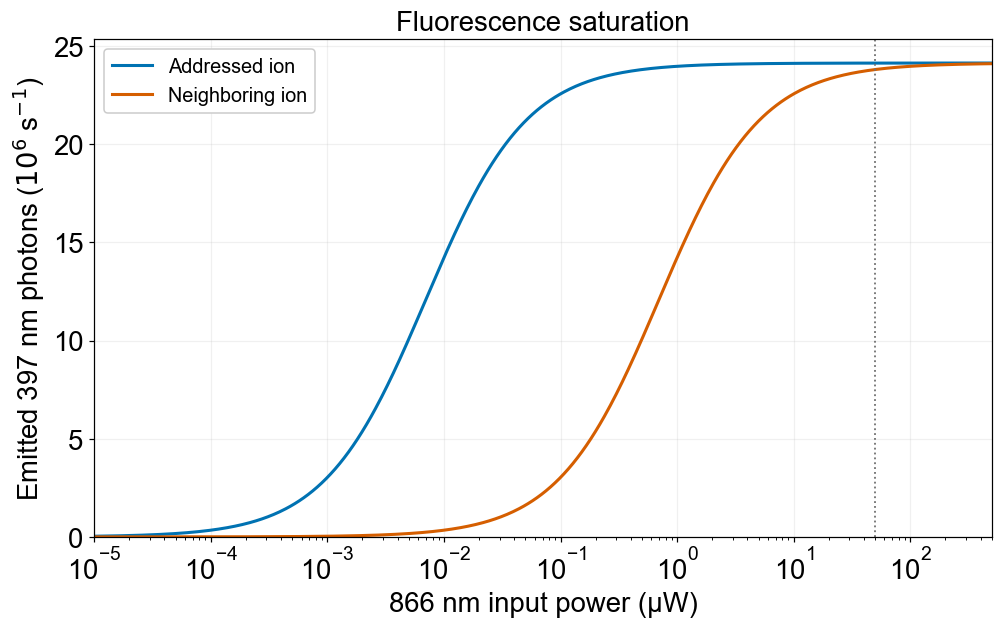

,quantity,value,units
0,Effective target repump parameter u,7183.399968,dimensionless
1,Effective repump half-saturation input power,0.006960,µW input (includes configured loss)
2,Target fluorescence / plateau,0.999861,fraction
3,Neighbor fluorescence / plateau,0.986270,fraction
4,Fluorescence ratio,-0.059437,dB
5,u required for -5 dB fluorescence,44.785054,dimensionless
6,866 input power for -5 dB fluorescence,0.311726,µW input (same coupling/overlap)
7,866 power at ions for -5 dB fluorescence,0.019669,µW at ion plane


<IPython.core.display.Markdown object>

In [6]:
repump_scanned = SR*power866_axis/POWER_866_UW
f_target = BRANCH_S*GAMMA*excited_population(SC, repump_scanned)
f_neighbor = BRANCH_S*GAMMA*excited_population(SC, LEAK*repump_scanned)
fig_rates, ax = plt.subplots(figsize=(9, 5.6), constrained_layout=True)
ax.semilogx(power866_axis, f_target/1e6, lw=2, color='#0072B2', label='Addressed ion')
ax.semilogx(power866_axis, f_neighbor/1e6, lw=2, color='#D55E00', label='Neighboring ion')
ax.axvline(POWER_866_UW, color='.45', ls=':', lw=1.2)
ax.set(xlim=POWER_866_SCAN_LIMITS_UW, ylim=(0, None), xlabel='866 nm input power (µW)',
       ylabel=r'Emitted 397 nm photons ($10^6$ s$^{-1}$)', title='Fluorescence saturation')
ax.legend(loc='upper left', facecolor='white', framealpha=1)
ax.grid(alpha=.18)
display(fig_rates)
fig_rates.savefig(OUTPUT_DIR/'fluorescence_absolute_rates.svg', bbox_inches='tight')
plt.close(fig_rates)
pd.DataFrame({'power_866_uw': power866_axis, 'power_866_at_ions_uw': power866_axis*TRANSMISSION_866, 'target_emitted_photons_s': f_target,
              'neighbor_emitted_photons_s': f_neighbor}).to_csv(OUTPUT_DIR/'fluorescence_absolute_rates.csv', index=False)

requested_ratio = 10**(TARGET_FLUORESCENCE_DB/10)
if not LEAK < requested_ratio < 1:
    raise ValueError('For the target-contrast calculation require c < requested fluorescence ratio < 1')
required_u = (requested_ratio-LEAK)/(LEAK*(1-requested_ratio))
required_power_uw = POWER_866_UW*required_u/U
half_saturation_power_uw = POWER_866_UW/U
summary = pd.DataFrame([
    {'quantity': 'Effective target repump parameter u', 'value': U, 'units': 'dimensionless'},
    {'quantity': 'Effective repump half-saturation input power', 'value': half_saturation_power_uw, 'units': 'µW input (includes configured loss)'},
    {'quantity': 'Target fluorescence / plateau', 'value': U/(1+U), 'units': 'fraction'},
    {'quantity': 'Neighbor fluorescence / plateau', 'value': LEAK*U/(1+LEAK*U), 'units': 'fraction'},
    {'quantity': 'Fluorescence ratio', 'value': float(to_db(NOMINAL_RATIO)), 'units': 'dB'},
    {'quantity': f'u required for {TARGET_FLUORESCENCE_DB:g} dB fluorescence', 'value': required_u, 'units': 'dimensionless'},
    {'quantity': f'866 input power for {TARGET_FLUORESCENCE_DB:g} dB fluorescence', 'value': required_power_uw, 'units': 'µW input (same coupling/overlap)'},
    {'quantity': f'866 power at ions for {TARGET_FLUORESCENCE_DB:g} dB fluorescence', 'value': required_power_uw*TRANSMISSION_866, 'units': 'µW at ion plane'},
])
display(summary)
summary.to_csv(OUTPUT_DIR/'operating_point_summary.csv', index=False)
display(Markdown(
    f'**Reduced-model result:** $\\widetilde{{s}}_{{397}}={SC:.3g}$, '
    f'$\\widetilde{{s}}_{{866}}={SR:.3g}$, and $u={U:.3g}$. '
    f'For {OPTICAL_CROSSTALK_DB:g} dB optical leakage, the predicted fluorescence ratio is '
    f'**{float(to_db(NOMINAL_RATIO)):.3f} dB**. '
    f'Reaching {TARGET_FLUORESCENCE_DB:g} dB instead requires approximately '
    f'**{1000*required_power_uw:.2f} nW input**, or **{1000*required_power_uw*TRANSMISSION_866:.2f} nW at the ions**, of 866 nm power under the same assumptions. '
    'This is a conditional rate-model estimate, not a calibrated local repump response.'))

## Coupling, beam-size convention, and the 397 nm spatial profile

These scenarios quantify assumptions instead of assigning an unsupported uncertainty bar. The π-component case is the default. The strongest single-component comparison uses branch fractions $\chi_{397}=2/3$ and $\chi_{866}=1/2$; weaker coupling reduces both effective Rabi frequencies. These are scalar comparisons, not a simulation of optical pumping.

If the supplied beam dimensions were **FWHM** instead of 1/e² widths, the same numerical width corresponds to a larger Gaussian radius by $\sqrt{2/\ln2}$, and the inferred peak intensity is smaller by $\ln2/2$. The table evaluates this change for both beams. If the ion is displaced, edit the local-overlap factors rather than changing the measured intensity ratio arbitrarily.

The separate spatial check centers the free-space 397 nm beam on the addressed ion, then puts the neighbor 5 µm away along either beam axis. For unequal cooling excitation, compute the two steady-state populations separately; the simple equal-cooling $r_F(c,u)$ expression is no longer used.

In [7]:
sensitivity_rows = []
for label, chi_c, chi_r, intensity_factor in (
    ('Default pi-component assumption', 1/3, 1/3, 1.0),
    ('Strongest single components', 2/3, 1/2, 1.0),
    ('10x weaker effective coupling on both legs', 1/30, 1/30, 1.0),
    ('Quoted widths interpreted as FWHM', DIPOLE_FRACTION_397, DIPOLE_FRACTION_866, np.log(2)/2),
):
    sc = I397*intensity_factor/saturation_intensity(LAMBDA_397_NM, BRANCH_S, chi_c)/detuning_factor(DETUNING_397_MHZ)
    sr = I866*intensity_factor/saturation_intensity(LAMBDA_866_NM, BRANCH_D, chi_r)/detuning_factor(DETUNING_866_MHZ)
    sensitivity_rows.append(dict(scenario=label, s397_tilde=sc, s866_tilde=sr, u=float(effective_u(sc, sr)),
        fluorescence_ratio_db=float(to_db(fluorescence_ratio(LEAK, sc, sr)))))
sensitivity_table = pd.DataFrame(sensitivity_rows)
display(sensitivity_table)
sensitivity_table.to_csv(OUTPUT_DIR/'coupling_and_width_sensitivity.csv', index=False)

cooling_scenarios = [('Uniform 397 nm excitation', 1.0)]
for axis_index, radius in enumerate(RADII_397_UM):
    cooling_scenarios.append((f'5 µm separation along 397 axis {axis_index+1} (w = {radius:g} µm)',
                              np.exp(-2*(ION_SEPARATION_UM/radius)**2)))
cooling_spatial_table = pd.DataFrame([
    dict(scenario=label, cooling_neighbor_ratio=a,
         fluorescence_ratio_db=float(to_db(fluorescence_ratio(LEAK, SC, SR, a))))
    for label, a in cooling_scenarios])
display(cooling_spatial_table)
cooling_spatial_table.to_csv(OUTPUT_DIR/'cooling_spatial_variation.csv', index=False)
print('SVG figures saved in:', OUTPUT_DIR.resolve())

                                  scenario  s397_tilde  s866_tilde           u  fluorescence_ratio_db
           Default pi-component assumption    0.760173  169.271031 7183.399968              -0.059437
               Strongest single components    1.520346  253.906547 8346.833742              -0.051202
10x weaker effective coupling on both legs    0.076017   16.927103 3632.259448              -0.116754
         Quoted widths interpreted as FWHM    0.263456   58.664869 4605.167745              -0.092354
                                     scenario  cooling_neighbor_ratio  fluorescence_ratio_db
                    Uniform 397 nm excitation                1.000000              -0.059437
 5 µm separation along 397 axis 1 (w = 20 µm)                0.882497              -0.309169
5 µm separation along 397 axis 2 (w = 100 µm)                0.995012              -0.069103
SVG figures saved in: /Users/yiyangzhi/GIT/integrated_trapped_ions/Gen_1_Paper/fluorescence_crosstalk_results_ca


,scenario,s397_tilde,s866_tilde,u,fluorescence_ratio_db
0,Default pi-component assumption,0.760173,169.271031,7183.399968,-0.059437
1,Strongest single components,1.520346,253.906547,8346.833742,-0.051202
2,10x weaker effective coupling on both legs,0.076017,16.927103,3632.259448,-0.116754
3,Quoted widths interpreted as FWHM,0.263456,58.664869,4605.167745,-0.092354


,scenario,cooling_neighbor_ratio,fluorescence_ratio_db
0,Uniform 397 nm excitation,1.000000,-0.059437
1,5 µm separation along 397 axis 1 (w = 20 µm),0.882497,-0.309169
2,5 µm separation along 397 axis 2 (w = 100 µm),0.995012,-0.069103


## Interpretation and sources

The supplied powers and tightly focused 866 nm mode can imply very strong repump driving. A near-zero fluorescence ratio in this reduced model means that both ions approach the same plateau, **not** that optical leakage has become large. Conversely, a low fluorescence ratio cannot uniquely determine optical leakage without the local saturation response. The default coupling and beam overlap are assumptions, and the powers are approximate.

This notebook follows the supplied steady-state rate model, neglecting inter-leg coherence, dark resonances, Zeeman optical pumping, ion motion and detection transients. At large inferred Rabi frequency, coherent dressing can materially change the fluorescence; a full optical Bloch or multilevel treatment, or a measured fluorescence-versus-repump-power calibration, is needed for a quantitative experimental prediction. The equal-cooling bound $c\le r_F\le1$ is specific to this model and its assumptions.

- Branching fractions: [Ramm et al., Physical Review Letters 111, 023004 (2013)](https://arxiv.org/abs/1305.0858); use $b=0.06435$.
- P-state lifetime: [Jin and Church, Physical Review A 49, 3463 (1994)](https://doi.org/10.1103/PhysRevA.49.3463); use $\tau_{P_{1/2}}=7.098$ ns, implying $\Gamma/(2\pi)\approx22.42$ MHz.
- Dipole/Rabi/saturation formalism: [Steck, *Rubidium 87 D Line Data*, optical transition and scattering sections](https://steck.us/alkalidata/). Only the general formalism is used; **no Rb atomic values** are used for calcium. The branch and coupling factors in the conversion above are stated explicitly.
- Coherent three-level comparison and transient fluorescence: [Nuñez Barreto et al., *Transient fluorescence with a single trapped ion* (2023)](https://arxiv.org/abs/2303.00650).

Run all cells from the top after changing the inputs. Figures export as **SVG only**, with editable Arial text, 18 pt axes/titles/ticks and embedded heatmap imagery. Numerical CSV files accompany the SVGs.

## Axial consistency: Gaussian overlap and measured optical ratio

Use **one channel: blue / Ion location −1**, with the same sliding **5 µm** pair and offset origin as the axial-contrast plot in `cross_talk_analysis_ca_2.ipynb`.

The Gaussian waist sets the local addressed-ion intensity loss, while the measured plot sets the changing neighbor/target intensity ratio. The Gaussian is centered at **offset zero in that plot**, as requested:
\[
g(\delta)=\exp[-2(\delta/w_x)^2],\quad w_x=0.94\;\mu\mathrm{m},\qquad
c(\delta)=\frac{I_{\mathrm{offsite,measured}}(\delta)}{I_{\mathrm{onsite,measured}}(\delta)}.
\]
Then
\[
\widetilde{s}_{866,t}(\delta)=\widetilde{s}_{866,0}\,g(\delta),\qquad
\widetilde{s}_{866,n}(\delta)=c(\delta)\widetilde{s}_{866,t}(\delta),
\]
\[
u_t(\delta)=\frac{3+2(1-b)/\widetilde{s}_{397}}{2b}\widetilde{s}_{866,t}(\delta),\qquad
r_F(\delta)=\frac{c(\delta)[1+u_t(\delta)]}{1+c(\delta)u_t(\delta)}.
\]

The measured addressed-ion profile amplitude is used **only in the ratio** $c(\delta)$. It is not also multiplied into $g(\delta)$, which would apply a second axial-attenuation factor. Optical leakage is **not fixed at −20 dB** in this section.

**Calibration and scope:** 0.94 µm is the axial 1/e² intensity radius, with the previously supplied **6 µm radius in the other direction**. A 50 µW input and 12 dB propagation loss leave 3.15 µW at the ion plane. The baseline saturation parameter is calculated from that power and beam area, with the stated π-component coupling assumption. Cooling excitation remains equal at both ions. The Gaussian factor represents local alignment loss, not an additional reduction in total transmitted beam power. The measured 830 nm optical-ratio curve is used as a spatial proxy for 866 nm. This combines a Gaussian overlap model with an empirical ratio curve; it is a conditional consistency estimate, rather than a full spatial beam reconstruction or an experimentally calibrated fluorescence response.

The nearest −5 dB fluorescence crossing is reported. All crossings and fluorescence levels are saved so that roots where both signals vanish are distinguishable from useful fluorescence contrast.

<Figure size 1550x570 with 2 Axes>
 axial_offset_um  gaussian_overlap  alignment_intensity_loss_db  optical_ratio_db  s866_target_tilde  s866_neighbor_tilde  fluorescence_ratio_db  target_over_plateau  neighbor_over_plateau
        1.766206          0.000858                    30.664872        -12.172194           0.145243             0.008808                   -5.0             0.860408               0.272085
Nearest -5 dB fluorescence crossing: +1.7662 µm.
At this same offset: optical ratio = -12.172 dB; Gaussian overlap = 0.00085805 (30.665 dB local intensity reduction).
Local s866: target = 0.145243; neighbor = 0.00880798.
Fluorescence / plateau: target = 0.8604; neighbor = 0.2721.
One Gaussian overlap factor is used; the optical ratio comes from the measured curve at that same offset.
Calibration: 0.94 × 6 µm radii, 50 µW input, 12 dB propagation loss, same coupling/cooling assumptions. The 830 nm intensity-ratio curve is a proxy for 866 nm.
Saved: /Users/yiyangzhi/GIT/integrated_t

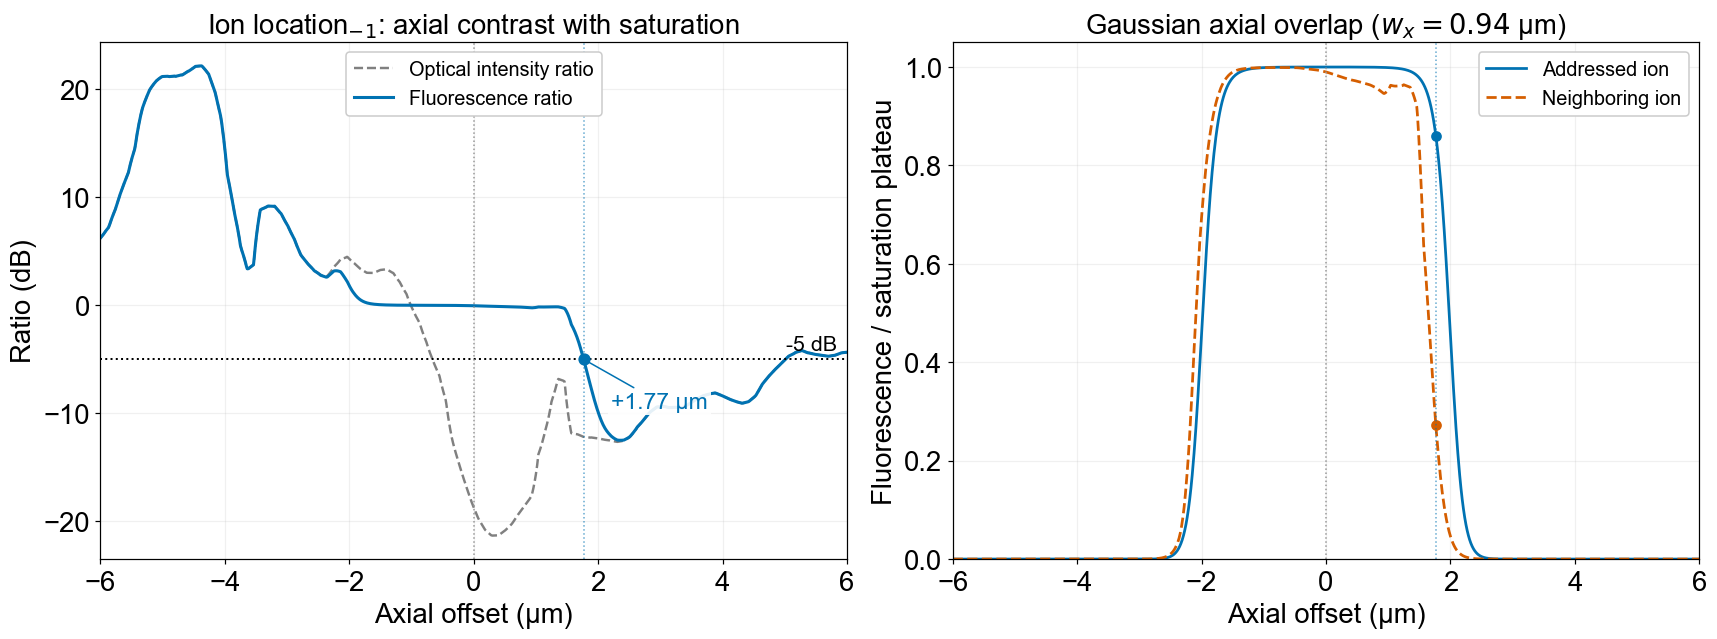

,axial_offset_um,gaussian_overlap,alignment_intensity_loss_db,optical_ratio_db,s866_target_tilde,s866_neighbor_tilde,fluorescence_ratio_db,target_over_plateau,neighbor_over_plateau
0,1.766206,0.000858,30.664872,-12.172194,0.145243,0.008808,-5.0,0.860408,0.272085


In [8]:
from scipy.optimize import brentq

AXIAL_SOURCE = PAPER_DIR / 'cross_talk_results_ca/publication_common_y/window_end_ratio_830nm_y19.5um_h75um.csv'
AXIAL_CHANNEL = 0  # displayed Ion location -1 / blue
AXIAL_WINDOW_UM = 5.0
AXIAL_GAUSSIAN_ZERO_UM = 0.0  # zero of the existing axial-contrast plot
AXIAL_WAIST_UM = float(RADII_866_UM[0])  # 0.94 um, 1/e^2 intensity radius
AXIAL_TARGET_DB = -5.0

axial_source = pd.read_csv(AXIAL_SOURCE)
required_columns = {'driven_ion', 'axial_offset_um', 'left_marker_x_um', 'right_marker_x_um',
                    'onsite_intensity', 'offsite_intensity', 'crosstalk_db'}
if not required_columns <= set(axial_source):
    raise ValueError('Re-run the sliding-window export in cross_talk_analysis_ca_2.ipynb')
axial_check = axial_source.loc[axial_source.driven_ion == AXIAL_CHANNEL].copy()
axial_check = axial_check.sort_values('axial_offset_um').reset_index(drop=True)
if len(axial_check) < 2 or axial_check.axial_offset_um.duplicated().any():
    raise ValueError('Need an increasing single-channel axial scan')
np.testing.assert_allclose(axial_check.right_marker_x_um-axial_check.left_marker_x_um, AXIAL_WINDOW_UM)
axial_offsets = axial_check.axial_offset_um.to_numpy()
measured_on = axial_check.onsite_intensity.to_numpy()
measured_off = axial_check.offsite_intensity.to_numpy()
A_cooling = 3+2*BRANCH_S/SC
F_plateau = BRANCH_S*GAMMA/A_cooling


def gaussian_axial_prediction(offset_um):
    """Gaussian on-site overlap + empirical, offset-dependent two-end intensity ratio."""
    offsets = np.asarray(offset_um, float)
    # Interpolate the two linear-intensity samples, then divide. NaN endpoints
    # remain invalid; np.interp is not asked to drop or bridge missing pixels.
    on = np.interp(offsets, axial_offsets, measured_on, left=np.nan, right=np.nan)
    off = np.interp(offsets, axial_offsets, measured_off, left=np.nan, right=np.nan)
    valid = np.isfinite(on) & np.isfinite(off) & (on > 0) & (off > 0)
    with np.errstate(divide='ignore', invalid='ignore'):
        c = np.where(valid, off/on, np.nan)
    overlap = np.exp(-2*((offsets-AXIAL_GAUSSIAN_ZERO_UM)/AXIAL_WAIST_UM)**2)
    st = SR*overlap
    sn = c*st
    p_t = excited_population(SC, st)
    p_n = excited_population(SC, np.where(valid, sn, 0.))
    with np.errstate(divide='ignore', invalid='ignore'):
        ratio = np.where(valid & (p_t > 0), p_n/p_t, np.nan)
    return dict(gaussian_overlap=overlap,
                alignment_intensity_loss_db=-to_db(overlap), optical_ratio=c,
                optical_ratio_db=to_db(c), s866_target_tilde=st, s866_neighbor_tilde=sn,
                u_target=U*overlap, fluorescence_ratio=ratio, fluorescence_ratio_db=to_db(ratio),
                target_over_plateau=A_cooling*p_t,
                neighbor_over_plateau=np.where(valid, A_cooling*p_n, np.nan),
                target_emitted_photons_s=BRANCH_S*GAMMA*p_t,
                neighbor_emitted_photons_s=np.where(valid, BRANCH_S*GAMMA*p_n, np.nan))


prediction = gaussian_axial_prediction(axial_offsets)
for key, values in prediction.items():
    axial_check[key] = values
np.testing.assert_allclose(axial_check.optical_ratio_db, axial_check.crosstalk_db, atol=1e-10)
# Independent check against the manuscript's analytic ratio formula.
c_values = axial_check.optical_ratio.to_numpy()
u_values = axial_check.u_target.to_numpy()
np.testing.assert_allclose(axial_check.fluorescence_ratio,
                          c_values*(1+u_values)/(1+c_values*u_values), rtol=1e-12)
np.testing.assert_allclose(gaussian_axial_prediction(AXIAL_GAUSSIAN_ZERO_UM)['gaussian_overlap'], 1.)
np.testing.assert_allclose(gaussian_axial_prediction(AXIAL_GAUSSIAN_ZERO_UM+AXIAL_WAIST_UM)['gaussian_overlap'],
                          np.exp(-2), rtol=1e-12)

# Solve roots using the same interpolation and Gaussian expression as the curves.
roots = []
residual = axial_check.fluorescence_ratio_db.to_numpy()-AXIAL_TARGET_DB
for index, (a, b) in enumerate(zip(axial_offsets[:-1], axial_offsets[1:])):
    fa, fb = residual[index:index+2]
    if not np.isfinite([fa, fb]).all():
        continue
    if fa == 0: roots.append(float(a))
    if fa*fb < 0:
        roots.append(float(brentq(
            lambda d: float(gaussian_axial_prediction(d)['fluorescence_ratio_db'])-AXIAL_TARGET_DB,
            a, b, xtol=1e-12)))
if np.isfinite(residual[-1]) and residual[-1] == 0:
    roots.append(float(axial_offsets[-1]))
records = []
for offset in sorted(set(round(root, 12) for root in roots), key=lambda d: abs(d-AXIAL_GAUSSIAN_ZERO_UM)):
    record = dict(axial_offset_um=offset)
    record.update({key: float(value) for key, value in gaussian_axial_prediction(offset).items()})
    np.testing.assert_allclose(record['fluorescence_ratio_db'], AXIAL_TARGET_DB, atol=1e-8)
    records.append(record)
axial_gaussian_crossings = pd.DataFrame(records)
if axial_gaussian_crossings.empty:
    raise RuntimeError('No requested fluorescence crossing in the exported offset range')
nearest = axial_gaussian_crossings.iloc[0]

fig_axial_consistency, axes = plt.subplots(1, 2, figsize=(15.5, 5.7), constrained_layout=True)
axes[0].plot(axial_offsets, axial_check.optical_ratio_db,
             color='.5', lw=1.6, ls='--', label='Optical intensity ratio')
axes[0].plot(axial_offsets, axial_check.fluorescence_ratio_db,
             color='#0072B2', lw=2, label='Fluorescence ratio')
axes[0].axhline(AXIAL_TARGET_DB, color='black', ls=':', lw=1.3)
axes[0].plot(nearest.axial_offset_um, AXIAL_TARGET_DB, 'o', color='#0072B2', ms=7)
axes[0].annotate(f'{nearest.axial_offset_um:+.2f} µm',
    xy=(nearest.axial_offset_um, AXIAL_TARGET_DB), xytext=(18, -32), textcoords='offset points',
    color='#0072B2', fontsize=15, arrowprops=dict(arrowstyle='-', color='#0072B2', lw=1),
    bbox=dict(facecolor='white', edgecolor='none', alpha=.9, pad=2))
axes[0].text(axial_offsets.max()-.15, AXIAL_TARGET_DB+.5,
             f'{AXIAL_TARGET_DB:g} dB', ha='right', va='bottom', fontsize=14)
axes[0].set(xlabel='Axial offset (µm)', ylabel='Ratio (dB)',
             title=r'Ion location$_{-1}$: axial contrast with saturation')
axes[0].legend(loc='upper center', fontsize=13, facecolor='white', framealpha=1)
axes[1].plot(axial_offsets, axial_check.target_over_plateau,
             color='#0072B2', lw=1.8, label='Addressed ion')
axes[1].plot(axial_offsets, axial_check.neighbor_over_plateau,
             color='#D55E00', lw=1.8, ls='--', label='Neighboring ion')
axes[1].plot(nearest.axial_offset_um, nearest.target_over_plateau, 'o', color='#0072B2', ms=6)
axes[1].plot(nearest.axial_offset_um, nearest.neighbor_over_plateau, 'o', color='#D55E00', ms=6)
axes[1].set(xlabel='Axial offset (µm)', ylabel='Fluorescence / saturation plateau', ylim=(0, 1.05),
             title=r'Gaussian axial overlap ($w_x = 0.94$ µm)')
axes[1].legend(loc='upper right', fontsize=13, facecolor='white', framealpha=1)
for ax in axes:
    ax.set_xlim(axial_offsets.min(), axial_offsets.max())
    ax.axvline(AXIAL_GAUSSIAN_ZERO_UM, color='.6', ls=':', lw=1)
    ax.axvline(nearest.axial_offset_um, color='#0072B2', ls=':', lw=1, alpha=.6)
    ax.grid(alpha=.18)
display(fig_axial_consistency)
axial_svg_path = OUTPUT_DIR/'axial_consistency_gaussian_overlap_w0p94um.svg'
fig_axial_consistency.savefig(axial_svg_path, bbox_inches='tight')
plt.close(fig_axial_consistency)
axial_check.to_csv(OUTPUT_DIR/'axial_consistency_gaussian_overlap_w0p94um.csv', index=False)
axial_gaussian_crossings.to_csv(OUTPUT_DIR/'axial_consistency_gaussian_overlap_crossings.csv', index=False)

summary_columns = ['axial_offset_um', 'gaussian_overlap', 'alignment_intensity_loss_db',
                   'optical_ratio_db', 's866_target_tilde', 's866_neighbor_tilde',
                   'fluorescence_ratio_db', 'target_over_plateau', 'neighbor_over_plateau']
display(axial_gaussian_crossings.head(1)[summary_columns])
print(f'Nearest {AXIAL_TARGET_DB:g} dB fluorescence crossing: {nearest.axial_offset_um:+.4f} µm.')
print(f'At this same offset: optical ratio = {nearest.optical_ratio_db:.3f} dB; '
      f'Gaussian overlap = {nearest.gaussian_overlap:.6g} '
      f'({nearest.alignment_intensity_loss_db:.3f} dB local intensity reduction).')
print(f'Local s866: target = {nearest.s866_target_tilde:.6g}; neighbor = {nearest.s866_neighbor_tilde:.6g}.')
print(f'Fluorescence / plateau: target = {nearest.target_over_plateau:.4f}; '
      f'neighbor = {nearest.neighbor_over_plateau:.4f}.')
print('One Gaussian overlap factor is used; the optical ratio comes from the measured curve at that same offset.')
print('Calibration: 0.94 × 6 µm radii, 50 µW input, 12 dB propagation loss, same coupling/cooling assumptions. '
      'The 830 nm intensity-ratio curve is a proxy for 866 nm.')
print('Saved:', axial_svg_path.resolve())

## Measured-profile colormap: axial displacement and 397 nm saturation

The map axes are **axial displacement** and **397 nm saturation around 1**. The peak 866 nm saturation is held fixed at the previously calculated power/loss estimate, approximately **169**. The **local** 866 nm saturation is a function of displacement, not an independent map axis.

Recenter the measured blue maximum at $x=0$ and normalize its linear intensity to $q(0)=1$ (0 dB). The two ends of the 5 µm window are at $\delta$ and $\delta+5$ µm. At zero displacement only the left/addressed-ion end is at the peak; the right/neighboring-ion end samples the same blue curve at $+5$ µm.
\[
\widetilde{s}_{866,t}(\delta)=\widetilde{s}_{866,\mathrm{peak}}q(\delta),\qquad
\widetilde{s}_{866,n}(\delta)=\widetilde{s}_{866,\mathrm{peak}}q(\delta+5),\quad
\widetilde{s}_{866,\mathrm{peak}}\approx169.
\]
The measured profile supplies **both local attenuation and the changing contrast**:
\[
c(\delta)=q(\delta+5)/q(\delta).
\]
Use the same three-level population response at each endpoint:
\[
p_P(s_c,s_r)=\left[3+2(1-b_D)/s_c+2b_D/s_r\right]^{-1},\qquad
R_F(\delta,s_c)=\frac{p_P(s_c,\widetilde{s}_{866,n}(\delta))}
{p_P(s_c,\widetilde{s}_{866,t}(\delta))}.
\]
The vertical coordinate is the **detuning-corrected** $s_c=\widetilde{s}_{397}$, scanned from 0.3 to 3. The color is $10\log_{10}R_F$; positive ratios are retained when the right window end is brighter. Cooling intensity is equal at both ions, and detection efficiencies are assumed corrected.

**Normalization:** the user-selected peak estimate comes from the earlier power/loss calculation (50 µW input, 12 dB loss, and the stated beam area and effective coupling). After setting that fixed peak value, this map uses **no Gaussian spatial attenuation or waist fit**. The profile is measured at 830 nm and used as a spatial proxy for 866 nm. A normalized profile alone does not independently calibrate its peak saturation. Linear interpolation preserves missing-data gaps; the display grid does not improve the native spatial resolution.

Requested −5, −4, −3, −2, and −1 dB contours are drawn **only if the computed map reaches those levels**. The companion figure shows the measured profile and the actual displacement-dependent saturation at both window ends.

<Figure size 1030x650 with 2 Axes>
<Figure size 1550x570 with 2 Axes>
                                   case  axial_displacement_um  s397_tilde  s866_target_tilde  s866_neighbor_tilde  fluorescence_ratio_db
Zero displacement; cooling saturation 1                    0.0         1.0         169.271031             1.248984              -0.090231
                Most negative map value                    4.1         3.0           3.786762             0.481571              -0.268487
Fixed peak 866 saturation = 169.271031; local values follow q(delta) and q(delta+5).
At zero displacement: local s866 = 169.2710, 1.2490; at s397=1, fluorescence ratio = -0.0902 dB.
Computed map range: -0.2685 to 0.1898 dB.
Requested contour levels present: []
No -1 to -5 dB contours exist within this parameter range at the selected peak saturation.
No Gaussian spatial factor is used; the measured profile sets local attenuation and contrast.
Map saved: /Users/yiyangzhi/GIT/integrated_trapped_ions/Gen_1_Paper/fl

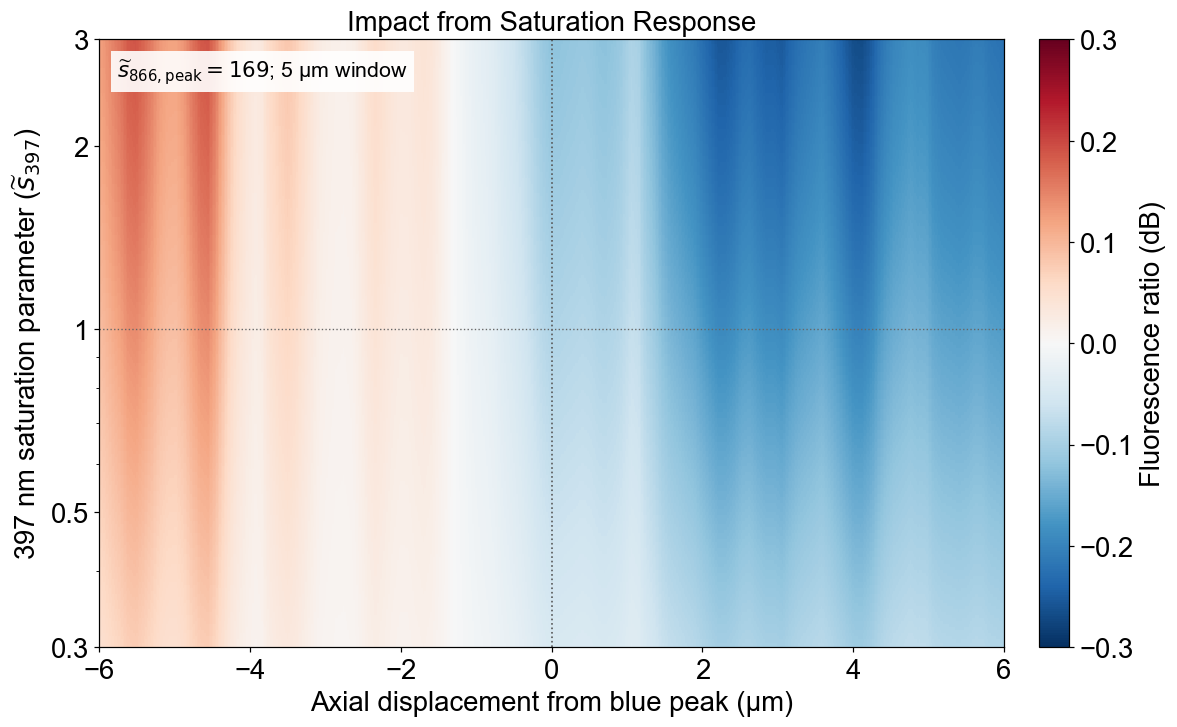

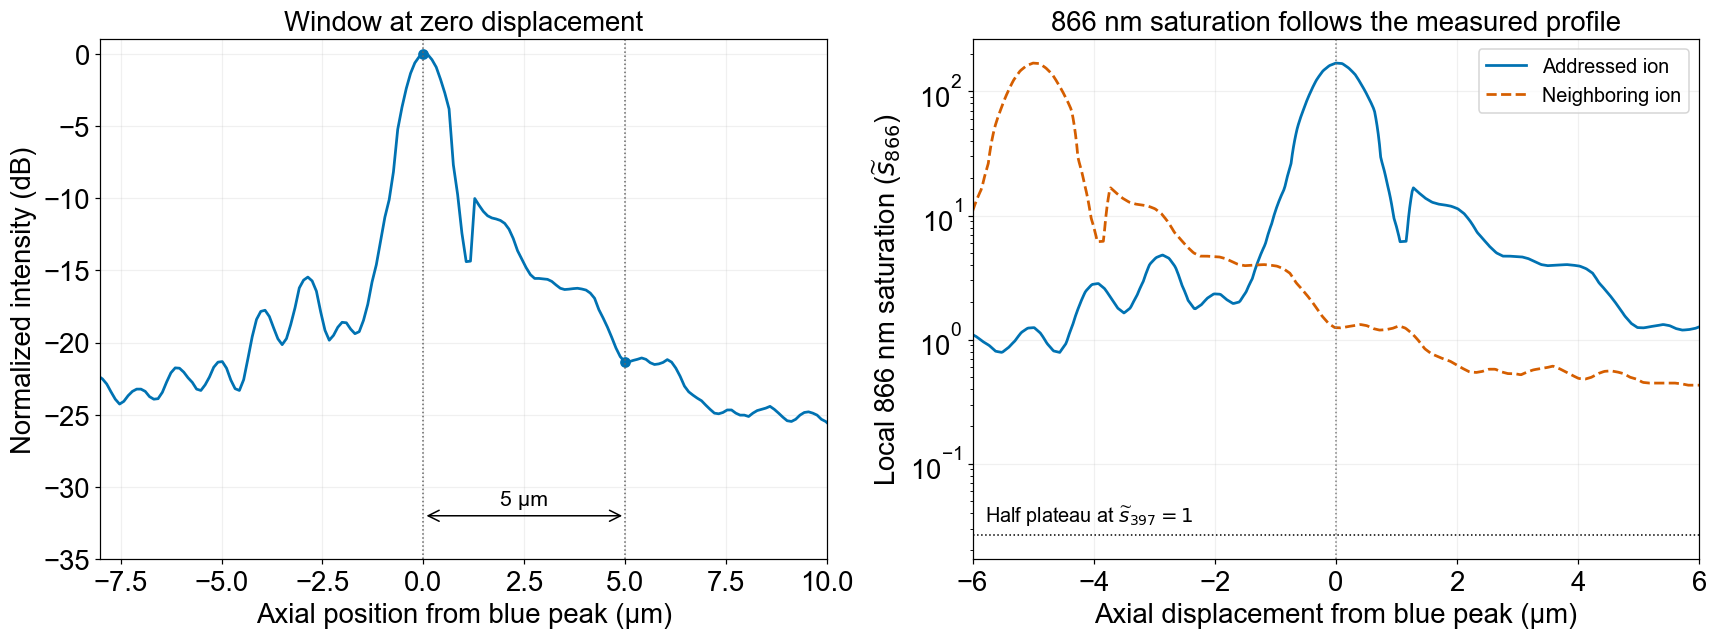

,case,axial_displacement_um,s397_tilde,s866_target_tilde,s866_neighbor_tilde,fluorescence_ratio_db
0,Zero displacement; cooling saturation 1,0.0,1.0,169.271031,1.248984,-0.090231
1,Most negative map value,4.1,3.0,3.786762,0.481571,-0.268487


In [9]:
from scipy.optimize import brentq
from matplotlib.colors import TwoSlopeNorm
from matplotlib.ticker import NullFormatter

PROFILE_MAP_SOURCE = PAPER_DIR / 'cross_talk_results_ca/publication_common_y/blue_peak_profile_830nm_y19.5um_h75um.csv'
PROFILE_MAP_S866_PEAK = float(SR)  # user-selected previous power/loss calibration, approximately 169
PROFILE_MAP_S397_LIMITS = (0.3, 3.0)
PROFILE_MAP_OFFSET_LIMITS_UM = (-6.0, 6.0)
PROFILE_MAP_WINDOW_UM = 5.0
PROFILE_MAP_CONTOURS_DB = [-5., -4., -3., -2., -1.]
PROFILE_MAP_EXAMPLE_S397 = 1.0

profile_native = pd.read_csv(PROFILE_MAP_SOURCE).sort_values('x_from_peak_um')
profile_x = profile_native.x_from_peak_um.to_numpy(dtype=float)
profile_q = profile_native.normalized_intensity.to_numpy(dtype=float)
if not np.isfinite(profile_x).all() or np.any(np.diff(profile_x) <= 0):
    raise ValueError('Require increasing native coordinates')
if not 0 < PROFILE_MAP_S397_LIMITS[0] < PROFILE_MAP_S397_LIMITS[1]:
    raise ValueError('Require increasing positive cooling-saturation limits')
if PROFILE_MAP_S866_PEAK <= 0 or not np.isfinite(PROFILE_MAP_S866_PEAK):
    raise ValueError('Require a finite positive fixed peak 866 saturation')


def measured_window_intensities(offset_um):
    """Sample the same measured profile at delta and delta+5, keeping missing data invalid."""
    offsets = np.asarray(offset_um, dtype=float)
    left = np.interp(offsets, profile_x, profile_q, left=np.nan, right=np.nan)
    right = np.interp(offsets+PROFILE_MAP_WINDOW_UM, profile_x, profile_q, left=np.nan, right=np.nan)
    return left, right


def measured_profile_fluorescence(offset_um, s397_tilde):
    """Local 866 saturation follows measured intensity; only cooling saturation is scanned."""
    left, right = measured_window_intensities(offset_um)
    left, right, cooling = np.broadcast_arrays(left, right, np.asarray(s397_tilde, dtype=float))
    if np.any(cooling <= 0) or not np.isfinite(cooling).all():
        raise ValueError('Cooling saturation must be finite and positive')
    valid = np.isfinite(left) & np.isfinite(right) & (left > 0) & (right > 0)
    target_s = PROFILE_MAP_S866_PEAK*left
    neighbor_s = PROFILE_MAP_S866_PEAK*right
    pt = excited_population(cooling, np.where(valid, target_s, 0.))
    pn = excited_population(cooling, np.where(valid, neighbor_s, 0.))
    with np.errstate(divide='ignore', invalid='ignore'):
        return np.where(valid & (pt > 0), pn/pt, np.nan)


map_offsets = np.linspace(*PROFILE_MAP_OFFSET_LIMITS_UM, 601)
map_s397 = np.geomspace(*PROFILE_MAP_S397_LIMITS, 201)
MAP_OFFSET, MAP_S397 = np.meshgrid(map_offsets, map_s397)
left_q, right_q = measured_window_intensities(map_offsets)
local_s866_target = PROFILE_MAP_S866_PEAK*left_q
local_s866_neighbor = PROFILE_MAP_S866_PEAK*right_q
profile_map_ratio = measured_profile_fluorescence(MAP_OFFSET, MAP_S397)
profile_map_db = to_db(profile_map_ratio)

# Checks: peak origin, 5 um window, and independent analytic fluorescence ratio.
q0_left, q0_right = measured_window_intensities(0.)
np.testing.assert_allclose(q0_left, 1., atol=1e-7)
np.testing.assert_allclose(measured_window_intensities(-PROFILE_MAP_WINDOW_UM)[1], 1., atol=1e-7)
valid_q = np.isfinite(left_q) & np.isfinite(right_q) & (left_q > 0) & (right_q > 0)
with np.errstate(divide='ignore', invalid='ignore'):
    c_map = right_q/left_q
    A_map = 3+2*BRANCH_S/MAP_S397
    u_map = A_map*local_s866_target[None, :]/(2*BRANCH_D)
    ratio_check = c_map[None, :]*(1+u_map)/(1+c_map[None, :]*u_map)
np.testing.assert_allclose(profile_map_ratio[:, valid_q], ratio_check[:, valid_q], rtol=1e-12)
np.testing.assert_allclose(local_s866_target[valid_q]/left_q[valid_q], PROFILE_MAP_S866_PEAK)
np.testing.assert_allclose(local_s866_neighbor[valid_q]/right_q[valid_q], PROFILE_MAP_S866_PEAK)

finite_map = profile_map_db[np.isfinite(profile_map_db)]
if not len(finite_map): raise ValueError('No valid profile-map values')
map_min_db, map_max_db = float(finite_map.min()), float(finite_map.max())
color_limit = max(.1, np.ceil(max(abs(map_min_db), abs(map_max_db))*10)/10)
available_levels = [level for level in PROFILE_MAP_CONTOURS_DB if map_min_db < level < map_max_db]
profile_map_figure, ax = plt.subplots(figsize=(10.3, 6.5), constrained_layout=True)
ax.set_yscale('log')
map_mesh = ax.pcolormesh(map_offsets, map_s397, profile_map_db, shading='auto',
    cmap='RdBu_r', norm=TwoSlopeNorm(vmin=-color_limit, vcenter=0, vmax=color_limit), rasterized=True)
if available_levels:
    map_contours = ax.contour(MAP_OFFSET, MAP_S397, profile_map_db,
        levels=available_levels, colors='black', linewidths=1.1)
    ax.clabel(map_contours, fmt=lambda value: f'{value:g} dB', fontsize=13)
ax.axvline(0., color='.35', ls=':', lw=1.1)
ax.axhline(PROFILE_MAP_EXAMPLE_S397, color='.4', ls=':', lw=.9)
ax.set(xlim=PROFILE_MAP_OFFSET_LIMITS_UM, ylim=PROFILE_MAP_S397_LIMITS,
       xlabel='Axial displacement from blue peak (µm)',
       ylabel=r'397 nm saturation parameter ($\widetilde{s}_{397}$)',
       title='Impact from Saturation Response')
ax.set_yticks([.3, .5, 1., 2., 3.])
ax.set_yticklabels(['0.3', '0.5', '1', '2', '3'])
ax.yaxis.set_minor_formatter(NullFormatter())
ax.text(.02, .97, rf'$\widetilde{{s}}_{{866,\mathrm{{peak}}}}={PROFILE_MAP_S866_PEAK:.0f}$; 5 µm window',
        transform=ax.transAxes, va='top', fontsize=14,
        bbox=dict(facecolor='white', edgecolor='none', alpha=.9, pad=4))
map_cb = profile_map_figure.colorbar(map_mesh, ax=ax, pad=.03)
map_cb.set_label('Fluorescence ratio (dB)')
map_cb.set_ticks(np.linspace(-color_limit, color_limit, 7))
display(profile_map_figure)
profile_map_svg = OUTPUT_DIR/'measured_profile_displacement_s397_map.svg'
profile_map_figure.savefig(profile_map_svg, bbox_inches='tight')
plt.close(profile_map_figure)
pd.DataFrame(dict(axial_displacement_um=MAP_OFFSET.ravel(), s397_tilde=MAP_S397.ravel(),
    fluorescence_ratio_db=profile_map_db.ravel(), s866_peak=PROFILE_MAP_S866_PEAK,
    s866_target_tilde=np.broadcast_to(local_s866_target, MAP_OFFSET.shape).ravel(),
    s866_neighbor_tilde=np.broadcast_to(local_s866_neighbor, MAP_OFFSET.shape).ravel())).to_csv(
        OUTPUT_DIR/'measured_profile_displacement_s397_map.csv', index=False)

# Companion view: geometry and the actual local 866 saturation as a function of displacement.
profile_window_figure, axes = plt.subplots(1, 2, figsize=(15.5, 5.7), constrained_layout=True)
axes[0].plot(profile_x, to_db(profile_q), color='#0072B2', lw=1.8)
axes[0].plot([0, PROFILE_MAP_WINDOW_UM], to_db([q0_left, q0_right]), 'o', color='#0072B2', ms=6)
for x_end in (0., PROFILE_MAP_WINDOW_UM): axes[0].axvline(x_end, color='.4', ls=':', lw=1)
axes[0].annotate('', xy=(0, -32), xytext=(PROFILE_MAP_WINDOW_UM, -32),
                 arrowprops=dict(arrowstyle='<->', lw=1))
axes[0].text(PROFILE_MAP_WINDOW_UM/2, -31.3, '5 µm', ha='center', fontsize=14)
axes[0].set(xlim=(-8, 10), ylim=(-35, 1), xlabel='Axial position from blue peak (µm)',
            ylabel='Normalized intensity (dB)', title='Window at zero displacement')
axes[1].semilogy(map_offsets, local_s866_target, color='#0072B2', lw=1.8, label='Addressed ion')
axes[1].semilogy(map_offsets, local_s866_neighbor, color='#D55E00', ls='--', lw=1.8, label='Neighboring ion')
axes[1].axvline(0., color='.5', ls=':', lw=1)
half_plateau_s = 2*BRANCH_D/(3+2*BRANCH_S/PROFILE_MAP_EXAMPLE_S397)
axes[1].axhline(half_plateau_s, color='black', ls=':', lw=1)
axes[1].text(PROFILE_MAP_OFFSET_LIMITS_UM[0]+.2, half_plateau_s*1.15,
             r'Half plateau at $\widetilde{s}_{397}=1$', fontsize=13, va='bottom')
axes[1].set(xlim=PROFILE_MAP_OFFSET_LIMITS_UM, xlabel='Axial displacement from blue peak (µm)',
            ylabel=r'Local 866 nm saturation ($\widetilde{s}_{866}$)',
            title='866 nm saturation follows the measured profile')
axes[1].legend(loc='upper right', fontsize=13)
for axis in axes: axis.grid(alpha=.18)
display(profile_window_figure)
profile_window_figure.savefig(OUTPUT_DIR/'measured_profile_local_s866_vs_displacement.svg', bbox_inches='tight')
plt.close(profile_window_figure)
pd.DataFrame(dict(axial_displacement_um=map_offsets, q_target=left_q, q_neighbor=right_q,
    s866_target_tilde=local_s866_target, s866_neighbor_tilde=local_s866_neighbor)).to_csv(
    OUTPUT_DIR/'measured_profile_local_s866_vs_displacement.csv', index=False)

example_ratio_db = to_db(measured_profile_fluorescence(map_offsets, PROFILE_MAP_EXAMPLE_S397))
zero_ratio_db = float(to_db(measured_profile_fluorescence(0., PROFILE_MAP_EXAMPLE_S397)))
min_flat_index = np.nanargmin(profile_map_db)
min_index = np.unravel_index(min_flat_index, profile_map_db.shape)
summary = pd.DataFrame([
 dict(case='Zero displacement; cooling saturation 1', axial_displacement_um=0., s397_tilde=1.,
      s866_target_tilde=PROFILE_MAP_S866_PEAK*float(q0_left),
      s866_neighbor_tilde=PROFILE_MAP_S866_PEAK*float(q0_right), fluorescence_ratio_db=zero_ratio_db),
 dict(case='Most negative map value', axial_displacement_um=MAP_OFFSET[min_index], s397_tilde=MAP_S397[min_index],
      s866_target_tilde=local_s866_target[min_index[1]],
      s866_neighbor_tilde=local_s866_neighbor[min_index[1]], fluorescence_ratio_db=map_min_db),
])
display(summary)
summary.to_csv(OUTPUT_DIR/'measured_profile_displacement_s397_summary.csv', index=False)
print(f'Fixed peak 866 saturation = {PROFILE_MAP_S866_PEAK:.6f}; local values follow q(delta) and q(delta+5).')
print(f'At zero displacement: local s866 = {PROFILE_MAP_S866_PEAK*q0_left:.4f}, '
      f'{PROFILE_MAP_S866_PEAK*q0_right:.4f}; at s397=1, fluorescence ratio = {zero_ratio_db:.4f} dB.')
print(f'Computed map range: {map_min_db:.4f} to {map_max_db:.4f} dB.')
print('Requested contour levels present:', available_levels)
if not available_levels:
    print('No -1 to -5 dB contours exist within this parameter range at the selected peak saturation.')
print('No Gaussian spatial factor is used; the measured profile sets local attenuation and contrast.')
print('Map saved:', profile_map_svg.resolve())

## Direct check: intensity in dB → 866 nm saturation versus displacement

The camera profile is an **intensity** ratio in dB:
\[
D(x)=10\log_{10}[I(x)/I_{\mathrm{peak}}].
\]
Since saturation is proportional to linear intensity at fixed coupling and detuning,
\[
\boxed{\widetilde{s}_{866}(x)=\widetilde{s}_{866,\mathrm{peak}}10^{D(x)/10}}.
\]
Use the selected peak estimate of approximately 169, and set the measured blue maximum to $x=0$. The measured intensity is converted back to linear units before interpolation. No Gaussian, window ratio, or fluorescence response is applied in this direct diagnostic. Saturation is dimensionless; a logarithmic saturation axis is used to show the dynamic range.

For example, 0 dB → 169, −10 dB → 16.9, −20 dB → 1.69, −30 dB → 0.169. A 20 dB intensity decrease divides saturation by **100**. An amplitude-dB factor of 20 is not used.

<Figure size 1500x570 with 2 Axes>
 axial_displacement_um  intensity_db  fraction_of_peak       s866
                  -5.0    -21.323624          0.007373   1.248016
                  -3.0    -15.830335          0.026120   4.421291
                  -2.0    -18.601049          0.013801   2.336027
                  -1.0    -11.947371          0.063865  10.810494
                  -0.5     -3.285525          0.469297  79.438342
                   0.0      0.000000          1.000000 169.271031
                   0.5     -2.416621          0.573242  97.033242
                   1.0    -13.170599          0.048188   8.156855
                   2.0    -11.715026          0.067375  11.404600
                   3.0    -15.598393          0.027552   4.663836
                   5.0    -21.320258          0.007379   1.248984
 intensity_db  fraction_of_peak       s866
          0.0          1.000000 169.271031
         -5.0          0.316228  53.528200
        -10.0          0.100000  16.927103
 

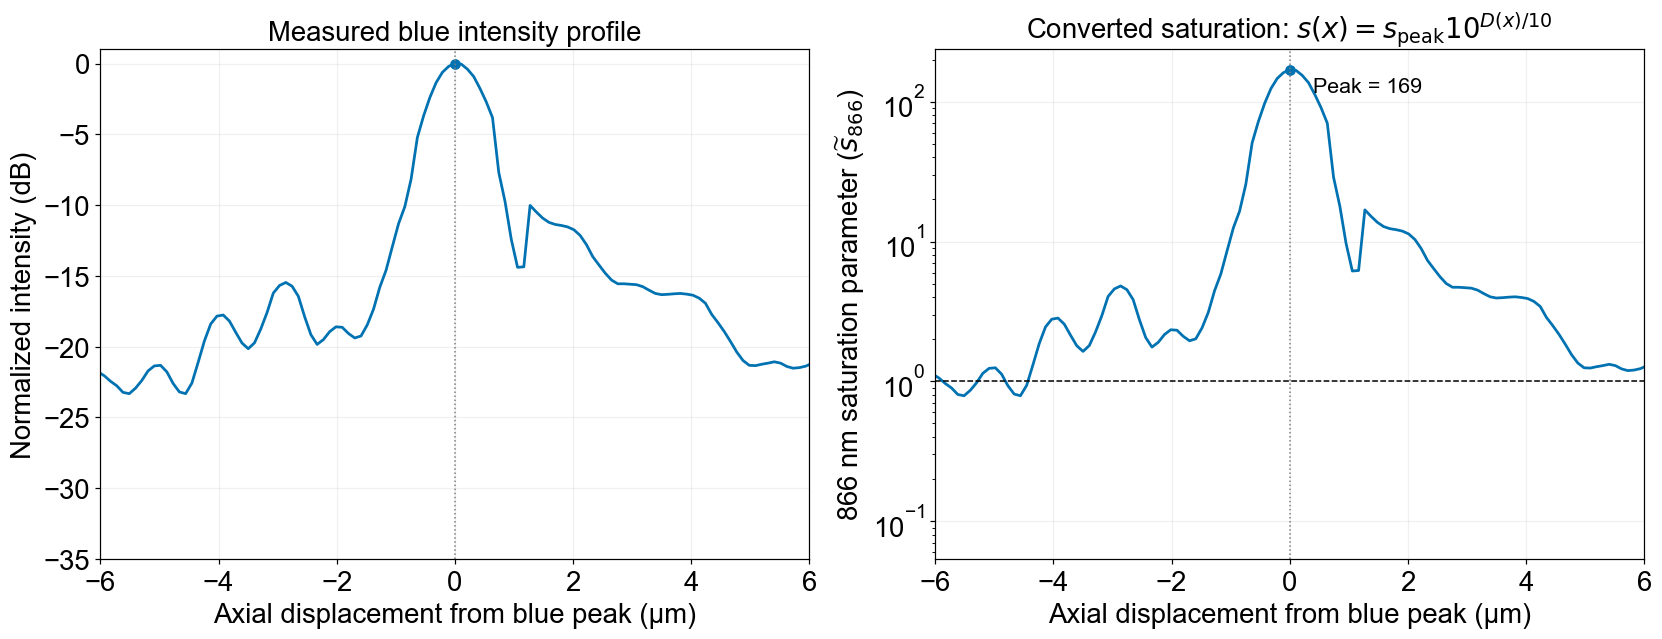

,axial_displacement_um,intensity_db,fraction_of_peak,s866
0,-5.0,-21.323624,0.007373,1.248016
1,-3.0,-15.830335,0.026120,4.421291
2,-2.0,-18.601049,0.013801,2.336027
3,-1.0,-11.947371,0.063865,10.810494
4,-0.5,-3.285525,0.469297,79.438342
5,0.0,0.000000,1.000000,169.271031
6,0.5,-2.416621,0.573242,97.033242
7,1.0,-13.170599,0.048188,8.156855
8,2.0,-11.715026,0.067375,11.404600
9,3.0,-15.598393,0.027552,4.663836


,intensity_db,fraction_of_peak,s866
0,0.0,1.000000,169.271031
1,-5.0,0.316228,53.528200
2,-10.0,0.100000,16.927103
3,-15.0,0.031623,5.352820
4,-20.0,0.010000,1.692710
5,-25.0,0.003162,0.535282
6,-30.0,0.001000,0.169271


In [10]:
DB_CHECK_SOURCE = PAPER_DIR / 'cross_talk_results_ca/publication_common_y/blue_peak_profile_830nm_y19.5um_h75um.csv'
DB_CHECK_PEAK_S866 = float(PROFILE_MAP_S866_PEAK)
DB_CHECK_X_LIMITS_UM = (-6., 6.)
db_check_profile = pd.read_csv(DB_CHECK_SOURCE).sort_values('x_from_peak_um')
db_check_x = db_check_profile.x_from_peak_um.to_numpy(float)
db_check_d = db_check_profile.normalized_intensity_db.to_numpy(float)
db_check_q = 10**(db_check_d/10)
db_check_s866 = DB_CHECK_PEAK_S866*db_check_q
# Check the dB conversion against the independent saved linear-intensity profile.
check_valid = np.isfinite(db_check_q) & np.isfinite(db_check_profile.normalized_intensity)
np.testing.assert_allclose(db_check_q[check_valid],
    db_check_profile.normalized_intensity.to_numpy()[check_valid], rtol=2e-6, atol=1e-10)
peak_index = int(np.nanargmax(db_check_d))
np.testing.assert_allclose(db_check_x[peak_index], 0., atol=1e-10)
np.testing.assert_allclose(db_check_d[peak_index], 0., atol=1e-7)
np.testing.assert_allclose(db_check_s866[peak_index], DB_CHECK_PEAK_S866, rtol=1e-7)

s866_db_figure, axes = plt.subplots(1, 2, figsize=(15, 5.7), constrained_layout=True)
axes[0].plot(db_check_x, db_check_d, color='#0072B2', lw=1.8)
axes[0].plot(0., 0., 'o', color='#0072B2', ms=6)
axes[0].set(ylabel='Normalized intensity (dB)', ylim=(-35, 1), title='Measured blue intensity profile')
axes[1].semilogy(db_check_x, db_check_s866, color='#0072B2', lw=1.8)
axes[1].plot(0., DB_CHECK_PEAK_S866, 'o', color='#0072B2', ms=6)
axes[1].annotate(f'Peak = {DB_CHECK_PEAK_S866:.0f}', xy=(0., DB_CHECK_PEAK_S866),
    xytext=(15, -5), textcoords='offset points', ha='left', va='top', fontsize=14)
axes[1].axhline(1., color='black', ls='--', lw=1)
axes[1].set(ylabel=r'866 nm saturation parameter ($\widetilde{s}_{866}$)',
            title=r'Converted saturation: $s(x)=s_{\mathrm{peak}}10^{D(x)/10}$',
            ylim=(DB_CHECK_PEAK_S866*10**(-35/10), DB_CHECK_PEAK_S866*1.4))
for axis in axes:
    axis.set(xlim=DB_CHECK_X_LIMITS_UM, xlabel='Axial displacement from blue peak (µm)')
    axis.axvline(0., color='.5', ls=':', lw=1)
    axis.grid(alpha=.18)
display(s866_db_figure)
s866_db_svg = OUTPUT_DIR/'s866_vs_axial_displacement_from_intensity_db.svg'
s866_db_figure.savefig(s866_db_svg, bbox_inches='tight')
plt.close(s866_db_figure)
pd.DataFrame(dict(axial_displacement_um=db_check_x, intensity_db=db_check_d,
    normalized_linear_intensity=db_check_q, s866=db_check_s866)).to_csv(
    OUTPUT_DIR/'s866_vs_axial_displacement_from_intensity_db.csv', index=False)

# Sample both signs of displacement. Interpolate LINEAR intensity, then convert back to dB.
sample_displacements = np.array([-5., -3., -2., -1., -.5, 0., .5, 1., 2., 3., 5.])
sample_q = np.interp(sample_displacements, db_check_x, db_check_q, left=np.nan, right=np.nan)
s866_displacement_samples = pd.DataFrame(dict(axial_displacement_um=sample_displacements,
    intensity_db=to_db(sample_q), fraction_of_peak=sample_q, s866=DB_CHECK_PEAK_S866*sample_q))
display(s866_displacement_samples)
s866_displacement_samples.to_csv(OUTPUT_DIR/'s866_axial_displacement_samples.csv', index=False)
db_levels = np.array([0., -5., -10., -15., -20., -25., -30.])
db_conversion_table = pd.DataFrame(dict(intensity_db=db_levels,
    fraction_of_peak=10**(db_levels/10), s866=DB_CHECK_PEAK_S866*10**(db_levels/10)))
display(db_conversion_table)
print('Intensity dB converted with 10**(D/10); the previous linear-profile calculations agree with this conversion.')
print('Only the addressed-ion local saturation is shown here; no neighboring-window ratio or fluorescence calculation.')
print('Saved:', s866_db_svg.resolve())

## Intensity contrast as the 5 µm window moves from the blue peak

The blue maximum is at $x=0$. At displacement $\delta$, the two window ends are $x_L=\delta$ and $x_R=\delta+5$ µm. Sample **the same blue curve** at both ends:
\[
C_I(\delta)=10\log_{10}\!\left[\frac{I(\delta+5)}{I(\delta)}\right]
=D(\delta+5)-D(\delta).
\]
This is a right-end/left-end **intensity ratio**, with no saturation or fluorescence response. Negative contrast means that the right end is dimmer. At $\delta=0$, the left end is at the measured maximum; the right end is at +5 µm. Convert native intensity dB to linear intensity **before interpolating** either end. Both displacements share the same peak origin; the original curve is not moved or independently normalized at each end.

<Figure size 880x560 with 1 Axes>
At δ=0: left end = 0 um, right end = 5 um; left = 0.000 dB, right = -21.320 dB, contrast = -21.320 dB.
Contrast is the difference of the two intensity-dB values after sampling in linear intensity.
Saved: /Users/yiyangzhi/GIT/integrated_trapped_ions/Gen_1_Paper/fluorescence_crosstalk_results_ca/measured_blue_5um_window_intensity_contrast.svg


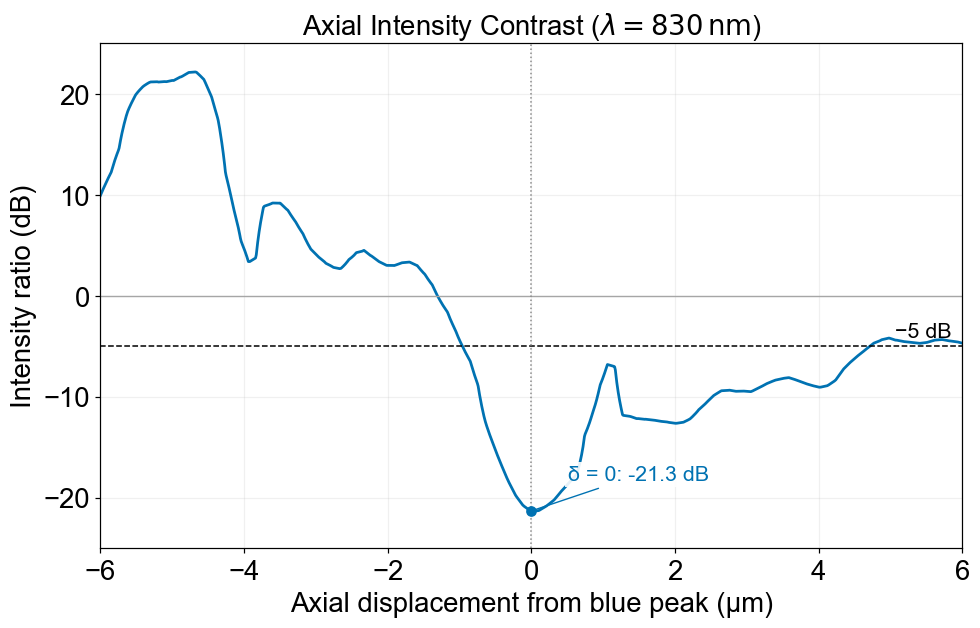

In [11]:
WINDOW_CONTRAST_SOURCE = PAPER_DIR / 'cross_talk_results_ca/publication_common_y/blue_peak_profile_830nm_y19.5um_h75um.csv'
WINDOW_CONTRAST_WIDTH_UM = 5.0
WINDOW_CONTRAST_OFFSET_LIMITS_UM = (-6., 6.)
window_native = pd.read_csv(WINDOW_CONTRAST_SOURCE).sort_values('x_from_peak_um')
window_x_native = window_native.x_from_peak_um.to_numpy(float)
window_db_native = window_native.normalized_intensity_db.to_numpy(float)
window_q_native = 10**(window_db_native/10)
if np.any(np.diff(window_x_native) <= 0):
    raise ValueError('Native profile coordinates must increase')


def peak_window_contrast(offset_um):
    """Right/left intensity contrast for two moving ends separated by exactly 5 um."""
    offsets = np.asarray(offset_um, dtype=float)
    q_left = np.interp(offsets, window_x_native, window_q_native, left=np.nan, right=np.nan)
    q_right = np.interp(offsets+WINDOW_CONTRAST_WIDTH_UM,
                        window_x_native, window_q_native, left=np.nan, right=np.nan)
    valid = np.isfinite(q_left) & np.isfinite(q_right) & (q_left > 0) & (q_right > 0)
    with np.errstate(divide='ignore', invalid='ignore'):
        d_left = np.where(valid, 10*np.log10(q_left), np.nan)
        d_right = np.where(valid, 10*np.log10(q_right), np.nan)
        contrast = np.where(valid, 10*np.log10(q_right/q_left), np.nan)
    return q_left, q_right, d_left, d_right, contrast


window_offsets = np.linspace(*WINDOW_CONTRAST_OFFSET_LIMITS_UM, 1201)
w_left, w_right, w_db_left, w_db_right, w_contrast = peak_window_contrast(window_offsets)
np.testing.assert_allclose(w_contrast, w_db_right-w_db_left, atol=1e-12)
w0_left, w0_right, w0_db_left, w0_db_right, w0_contrast = peak_window_contrast(0.)
np.testing.assert_allclose(w0_left, 1., atol=1e-7)
np.testing.assert_allclose(w0_db_left, 0., atol=1e-7)

window_contrast_figure, ax = plt.subplots(figsize=(8.8, 5.6), constrained_layout=True)
ax.plot(window_offsets, w_contrast, color='#0072B2', lw=1.8)
ax.axhline(0., color='.65', lw=.9)
ax.axhline(-5., color='black', ls='--', lw=1.)
ax.text(WINDOW_CONTRAST_OFFSET_LIMITS_UM[1]-.15, -4.5, '−5 dB',
        ha='right', va='bottom', fontsize=14)
ax.axvline(0., color='.55', ls=':', lw=1.)
ax.plot(0., w0_contrast, 'o', color='#0072B2', ms=6)
ax.annotate(f'δ = 0: {float(w0_contrast):.1f} dB', xy=(0., w0_contrast),
    xytext=(24, 20), textcoords='offset points', fontsize=14, color='#0072B2',
    arrowprops=dict(arrowstyle='-', color='#0072B2', lw=.9),
    bbox=dict(facecolor='white', edgecolor='none', alpha=.9, pad=2))
wave = int(window_native.wavelength_nm.iloc[0])
finite_contrast = w_contrast[np.isfinite(w_contrast)]
y_limits = (5*np.floor((min(finite_contrast.min(), -5)-1)/5),
            5*np.ceil((max(finite_contrast.max(), 0)+1)/5))
ax.set(xlim=WINDOW_CONTRAST_OFFSET_LIMITS_UM, ylim=y_limits,
       xlabel='Axial displacement from blue peak (µm)', ylabel='Intensity ratio (dB)',
       title=rf'Axial Intensity Contrast ($\lambda = {wave}\,\mathrm{{nm}}$)')
ax.grid(alpha=.18)
display(window_contrast_figure)
window_contrast_svg = OUTPUT_DIR/'measured_blue_5um_window_intensity_contrast.svg'
window_contrast_figure.savefig(window_contrast_svg, bbox_inches='tight')
plt.close(window_contrast_figure)
window_contrast_table = pd.DataFrame(dict(axial_displacement_um=window_offsets,
    left_end_from_peak_um=window_offsets, right_end_from_peak_um=window_offsets+WINDOW_CONTRAST_WIDTH_UM,
    left_normalized_intensity=w_left, right_normalized_intensity=w_right,
    left_intensity_db=w_db_left, right_intensity_db=w_db_right, intensity_contrast_db=w_contrast))
window_contrast_table.to_csv(OUTPUT_DIR/'measured_blue_5um_window_intensity_contrast.csv', index=False)
print(f'At δ=0: left end = 0 um, right end = {WINDOW_CONTRAST_WIDTH_UM:g} um; '
      f'left = {float(w0_db_left):.3f} dB, right = {float(w0_db_right):.3f} dB, '
      f'contrast = {float(w0_contrast):.3f} dB.')
print('Contrast is the difference of the two intensity-dB values after sampling in linear intensity.')
print('Saved:', window_contrast_svg.resolve())

## Expected fluorescence contrast between the two ions

Use the measured blue profile and the same moving 5 µm window. Hold $\widetilde{s}_{397}=1$ at both ions, and use the selected peak 866 nm saturation of approximately 169. The local saturation follows measured **linear intensity**, converted from intensity dB:
\[
s_t(\delta)=s_{866,\mathrm{peak}}10^{D_L(\delta)/10},\quad
s_n(\delta)=s_{866,\mathrm{peak}}10^{D_R(\delta)/10},\quad
c(\delta)=10^{[D_R(\delta)-D_L(\delta)]/10}.
\]
Then
\[
u_t(\delta)=\frac{3+2(1-b_D)/\widetilde{s}_{397}}{2b_D}s_t(\delta),\qquad
C_F(\delta)=10\log_{10}\!\left[\frac{c(\delta)[1+u_t(\delta)]}{1+c(\delta)u_t(\delta)}\right].
\]
The plotted quantity is the neighboring-ion fluorescence divided by addressed-ion fluorescence, in dB. Background-subtracted, efficiency-corrected fluorescence is assumed; a common collection time and detection efficiency cancel. There is no count calibration or extra Gaussian loss. This is a prediction of the supplied steady-state rate model, using the 830 nm spatial profile as a proxy for 866 nm.

<Figure size 880x560 with 1 Axes>
             case  axial_displacement_um  s866_addressed  s866_neighbor  optical_intensity_ratio_db  fluorescence_ratio_db
Zero displacement                   0.00      169.271031       1.248984                  -21.320258              -0.090231
    Minimum ratio                   4.11        3.769560       0.481033                   -8.941159              -0.201877
    Maximum ratio                  -4.56        0.788836     109.518071                   21.424988               0.142025
Ratio convention: neighboring / addressed ion; negative dB means the neighbor is dimmer.
At zero: ratio = 0.979438 (97.944%), -0.090231 dB.
Saved: /Users/yiyangzhi/GIT/integrated_trapped_ions/Gen_1_Paper/fluorescence_crosstalk_results_ca/expected_two_ion_fluorescence_contrast_vs_displacement.svg


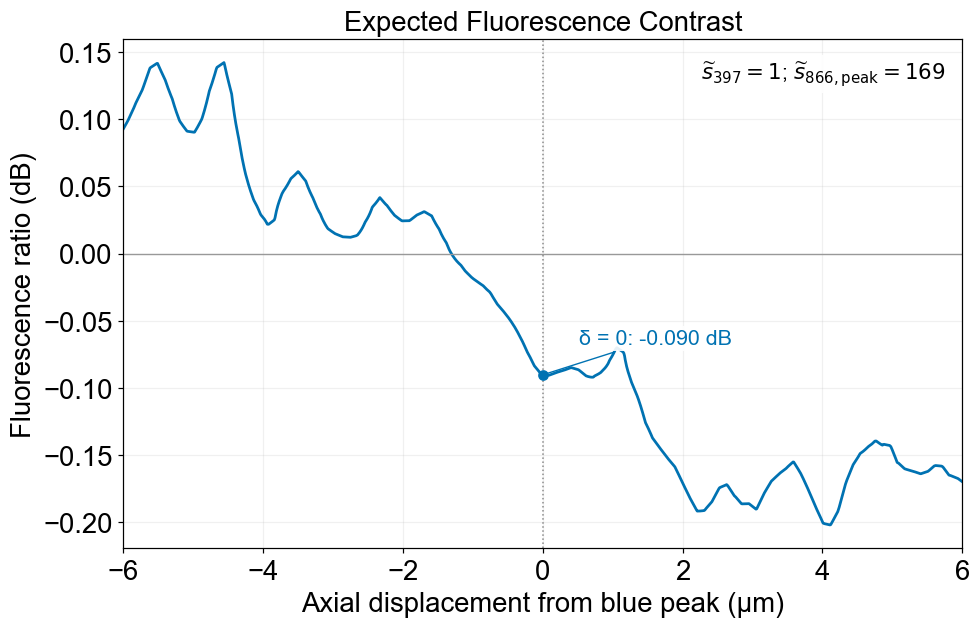

,case,axial_displacement_um,s866_addressed,s866_neighbor,optical_intensity_ratio_db,fluorescence_ratio_db
600,Zero displacement,0.00,169.271031,1.248984,-21.320258,-0.090231
1011,Minimum ratio,4.11,3.769560,0.481033,-8.941159,-0.201877
144,Maximum ratio,-4.56,0.788836,109.518071,21.424988,0.142025


In [13]:
ION_FLUOR_S397_TILDE = 1.0
ION_FLUOR_S866_PEAK = float(PROFILE_MAP_S866_PEAK)  # selected peak normalization, about 169
ION_FLUOR_OFFSET_LIMITS_UM = (-6., 6.)
ion_fluor_offsets = np.linspace(*ION_FLUOR_OFFSET_LIMITS_UM, 1201)
ion_ql, ion_qr, ion_dl, ion_dr, ion_optical_contrast_db = peak_window_contrast(ion_fluor_offsets)
ion_st = ION_FLUOR_S866_PEAK*ion_ql
ion_sn = ION_FLUOR_S866_PEAK*ion_qr
ion_valid = np.isfinite(ion_st) & np.isfinite(ion_sn) & (ion_st > 0) & (ion_sn > 0)
ion_c = 10**(ion_optical_contrast_db/10)
ion_u = (3+2*BRANCH_S/ION_FLUOR_S397_TILDE)*ion_st/(2*BRANCH_D)
ion_ratio = ion_c*(1+ion_u)/(1+ion_c*ion_u)
ion_contrast_db = to_db(ion_ratio)
# Verify against populations evaluated separately at the two local saturation values.
ion_pt = excited_population(ION_FLUOR_S397_TILDE, np.where(ion_valid, ion_st, 0.))
ion_pn = excited_population(ION_FLUOR_S397_TILDE, np.where(ion_valid, ion_sn, 0.))
np.testing.assert_allclose(ion_ratio[ion_valid], ion_pn[ion_valid]/ion_pt[ion_valid], rtol=1e-12)
np.testing.assert_allclose(ion_sn[ion_valid]/ion_st[ion_valid], ion_c[ion_valid], rtol=1e-12)

ion_fluor_table = pd.DataFrame(dict(axial_displacement_um=ion_fluor_offsets,
    s397_tilde=ION_FLUOR_S397_TILDE, s866_peak=ION_FLUOR_S866_PEAK,
    s866_addressed=ion_st, s866_neighbor=ion_sn, optical_intensity_ratio_db=ion_optical_contrast_db,
    fluorescence_ratio=ion_ratio, fluorescence_ratio_db=ion_contrast_db))
zero_ion = ion_fluor_table.loc[np.isclose(ion_fluor_table.axial_displacement_um, 0.)].iloc[0]
min_ion = ion_fluor_table.loc[ion_fluor_table.fluorescence_ratio_db.idxmin()]
max_ion = ion_fluor_table.loc[ion_fluor_table.fluorescence_ratio_db.idxmax()]

ion_fluor_figure, ax = plt.subplots(figsize=(8.8, 5.6), constrained_layout=True)
ax.plot(ion_fluor_offsets, ion_contrast_db, color='#0072B2', lw=1.8)
ax.axhline(0., color='.6', lw=.9)
ax.axvline(0., color='.55', ls=':', lw=1)
ax.plot(0., zero_ion.fluorescence_ratio_db, 'o', color='#0072B2', ms=6)
ax.annotate(f'δ = 0: {zero_ion.fluorescence_ratio_db:.3f} dB',
    xy=(0., zero_ion.fluorescence_ratio_db), xytext=(24, 20), textcoords='offset points',
    fontsize=14, color='#0072B2', arrowprops=dict(arrowstyle='-', color='#0072B2', lw=.9),
    bbox=dict(facecolor='white', edgecolor='none', alpha=.9, pad=2))
ax.text(.98, .96, rf'$\widetilde{{s}}_{{397}}={ION_FLUOR_S397_TILDE:g}$; '
    rf'$\widetilde{{s}}_{{866,\mathrm{{peak}}}}={ION_FLUOR_S866_PEAK:.0f}$',
    transform=ax.transAxes, ha='right', va='top', fontsize=14,
    bbox=dict(facecolor='white', edgecolor='none', alpha=.9, pad=3))
ax.set(xlim=ION_FLUOR_OFFSET_LIMITS_UM, xlabel='Axial displacement from blue peak (µm)',
       ylabel='Fluorescence ratio (dB)', title='Expected Fluorescence Contrast')
ax.grid(alpha=.18)
display(ion_fluor_figure)
ion_fluor_svg = OUTPUT_DIR/'expected_two_ion_fluorescence_contrast_vs_displacement.svg'
ion_fluor_figure.savefig(ion_fluor_svg, bbox_inches='tight')
plt.close(ion_fluor_figure)
ion_fluor_table.to_csv(OUTPUT_DIR/'expected_two_ion_fluorescence_contrast_vs_displacement.csv', index=False)
ion_fluor_summary = pd.DataFrame([zero_ion, min_ion, max_ion])
ion_fluor_summary.insert(0, 'case', ['Zero displacement', 'Minimum ratio', 'Maximum ratio'])
display(ion_fluor_summary[['case', 'axial_displacement_um', 's866_addressed', 's866_neighbor',
                         'optical_intensity_ratio_db', 'fluorescence_ratio_db']])
print('Ratio convention: neighboring / addressed ion; negative dB means the neighbor is dimmer.')
print(f'At zero: ratio = {zero_ion.fluorescence_ratio:.6f} '
      f'({100*zero_ion.fluorescence_ratio:.3f}%), {zero_ion.fluorescence_ratio_db:.6f} dB.')
print('Saved:', ion_fluor_svg.resolve())

## Alternative: 0.94 µm Gaussian axial attenuation, measured window contrast

This alternative replaces the **addressed-ion intensity decrease** by a Gaussian with its center at the measured blue peak ($\delta=0$), retaining the measured optical contrast of the moving 5 µm window:
\[
s_t(\delta)=s_{866,\mathrm{peak}}e^{-2(\delta/0.94\;\mu\mathrm m)^2},\qquad
c(\delta)=10^{C_I(\delta)/10},\qquad s_n(\delta)=c(\delta)s_t(\delta).
\]
Use the selected $s_{866,\mathrm{peak}}\approx169$ and fixed detuning-corrected $\widetilde{s}_{397}=1$. Then evaluate both fluorescence responses in the same rate model.

Only one Gaussian overlap factor is used. The measured on-site profile is not multiplied into that factor. The neighboring intensity is derived from the measured contrast at the **same displacement**; a separate Gaussian at $\delta+5$ would instead impose a Gaussian-only contrast curve. This is a **hybrid assumption**, because the measured wings are not Gaussian. The orange comparison curve retains both measured local intensities. Both use the same blue-peak origin, unlike the earlier balanced-marker example.

### Ion +1 (orange) and the combined plot

Apply the same Gaussian addressed-ion attenuation, peak saturation and cooling parameters to the orange channel. Recenter its own measured maximum at zero. Its neighbor lies **5 µm to the left**, so use $c_{+1}(\delta)=q_{+1}(\delta-5)/q_{+1}(\delta)$. Positive axial offsets mean the same physical direction for both channels; the orange offset axis is not reflected. The combined plot shows the two ion channels, with dotted reference guides removed. Solid annotation pointers mark the nearest −5 dB fluorescence crossing for each channel.


<Figure size 820x520 with 1 Axes>
 axial_displacement_um  gaussian_overlap  s866_addressed  s866_neighbor  optical_ratio_db  fluorescence_ratio_db
              1.744598          0.001019        0.172451       0.009982        -12.374455                   -5.0
 axial_displacement_um  gaussian_overlap  s866_addressed  s866_neighbor  optical_ratio_db  fluorescence_ratio_db
                   0.0          1.000000      169.271031       1.248984        -21.320258              -0.090231
                   0.5          0.567868       96.123542       1.286585        -18.733912              -0.087086
                   1.0          0.103989       17.602370       2.734729         -8.086569              -0.035242
                   1.5          0.006141        1.039458       0.062896        -12.181862              -1.414066
                   2.0          0.000117        0.019794       0.001079        -12.635290             -10.380708
Gaussian is centered at the measured blue peak, delta=0; cooli

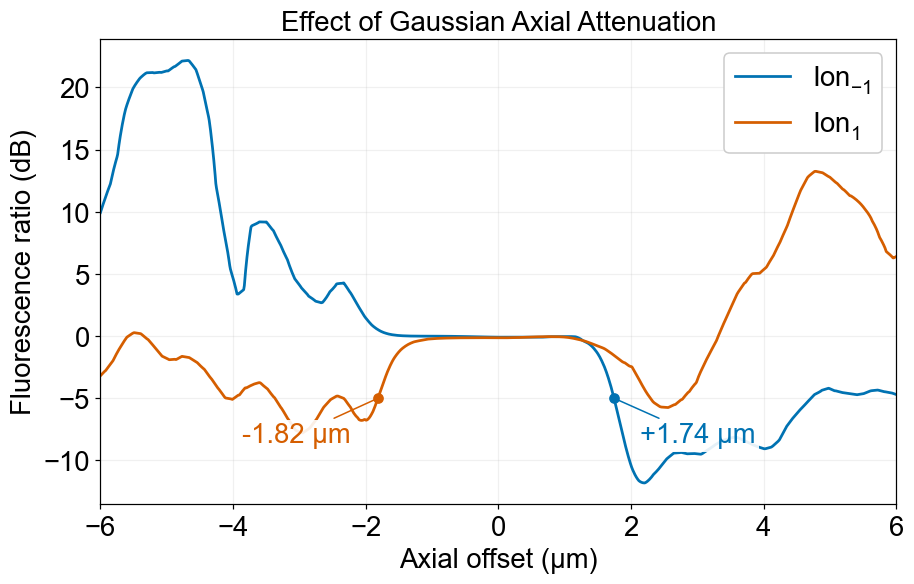

,axial_displacement_um,gaussian_overlap,s866_addressed,s866_neighbor,optical_ratio_db,fluorescence_ratio_db
0,1.744598,0.001019,0.172451,0.009982,-12.374455,-5.0


,axial_displacement_um,gaussian_overlap,s866_addressed,s866_neighbor,optical_ratio_db,fluorescence_ratio_db
0,0.0,1.000000,169.271031,1.248984,-21.320258,-0.090231
1,0.5,0.567868,96.123542,1.286585,-18.733912,-0.087086
2,1.0,0.103989,17.602370,2.734729,-8.086569,-0.035242
3,1.5,0.006141,1.039458,0.062896,-12.181862,-1.414066
4,2.0,0.000117,0.019794,0.001079,-12.635290,-10.380708


,ion_location,axial_displacement_um,optical_ratio_db,s866_addressed,s866_neighbor,fluorescence_ratio_db
0,-1,1.744598,-12.374455,0.172451,0.009982,-5.0
2,1,-1.815248,-10.472684,0.097597,0.008753,-5.0


In [14]:
from scipy.optimize import brentq

GAUSS_COMPARE_WAIST_UM = 0.94
GAUSS_COMPARE_S397 = 1.0
GAUSS_COMPARE_PEAK_S866 = float(PROFILE_MAP_S866_PEAK)
GAUSS_COMPARE_LIMITS_UM = (-6., 6.)
GAUSS_COMPARE_TARGET_DB = -5.


def gaussian_peak_origin_fluorescence(offset_um):
    ql, qr, dl, dr, contrast = peak_window_contrast(offset_um)
    offsets = np.asarray(offset_um, float)
    overlap = np.exp(-2*(offsets/GAUSS_COMPARE_WAIST_UM)**2)
    local_st = GAUSS_COMPARE_PEAK_S866*overlap
    local_c = 10**(contrast/10)
    local_sn = local_c*local_st
    valid = np.isfinite(local_c) & (local_c > 0)
    local_pt = excited_population(GAUSS_COMPARE_S397, local_st)
    local_pn = excited_population(GAUSS_COMPARE_S397, np.where(valid, local_sn, 0.))
    with np.errstate(divide='ignore', invalid='ignore'):
        ratio = np.where(valid & (local_pt > 0), local_pn/local_pt, np.nan)
    return dict(gaussian_overlap=overlap, s866_addressed=local_st, s866_neighbor=local_sn,
                optical_ratio_db=contrast, fluorescence_ratio_db=to_db(ratio))


gc_offsets = np.linspace(*GAUSS_COMPARE_LIMITS_UM, 1201)
gc = gaussian_peak_origin_fluorescence(gc_offsets)
gc_ql, gc_qr, _, _, gc_optical_db = peak_window_contrast(gc_offsets)
gc_valid = np.isfinite(gc_ql) & np.isfinite(gc_qr) & (gc_ql > 0) & (gc_qr > 0)
gc_measured_pt = excited_population(GAUSS_COMPARE_S397, np.where(gc_valid, GAUSS_COMPARE_PEAK_S866*gc_ql, 0.))
gc_measured_pn = excited_population(GAUSS_COMPARE_S397, np.where(gc_valid, GAUSS_COMPARE_PEAK_S866*gc_qr, 0.))
with np.errstate(divide='ignore', invalid='ignore'):
    gc_measured_db = np.where(gc_valid, to_db(gc_measured_pn/gc_measured_pt), np.nan)
np.testing.assert_allclose(gaussian_peak_origin_fluorescence(0.)['s866_addressed'], GAUSS_COMPARE_PEAK_S866)
np.testing.assert_allclose(gaussian_peak_origin_fluorescence(GAUSS_COMPARE_WAIST_UM)['gaussian_overlap'], np.exp(-2))
np.testing.assert_allclose(gaussian_peak_origin_fluorescence(0.)['fluorescence_ratio_db'],
    float(gc_measured_db[np.flatnonzero(np.isclose(gc_offsets,0.))[0]]), atol=1e-10)
# Check the ratio against the independent analytic expression.
gc_c = 10**(gc_optical_db/10)
gc_u = (3+2*BRANCH_S/GAUSS_COMPARE_S397)*gc['s866_addressed']/(2*BRANCH_D)
np.testing.assert_allclose(10**(gc['fluorescence_ratio_db'][gc_valid]/10),
    (gc_c*(1+gc_u)/(1+gc_c*gc_u))[gc_valid], rtol=1e-12)

gc_roots = []
gc_residual = gc['fluorescence_ratio_db']-GAUSS_COMPARE_TARGET_DB
for i, (a, b) in enumerate(zip(gc_offsets[:-1], gc_offsets[1:])):
    fa, fb = gc_residual[i:i+2]
    if np.isfinite([fa,fb]).all() and fa*fb < 0:
        root = brentq(lambda d: float(gaussian_peak_origin_fluorescence(d)['fluorescence_ratio_db'])-GAUSS_COMPARE_TARGET_DB,
                       a, b, xtol=1e-12)
        gc_roots.append(root)
gc_root_records = []
for offset in sorted(gc_roots, key=abs):
    row = dict(axial_displacement_um=offset)
    row.update({key: float(value) for key,value in gaussian_peak_origin_fluorescence(offset).items()})
    np.testing.assert_allclose(row['fluorescence_ratio_db'], GAUSS_COMPARE_TARGET_DB, atol=1e-8)
    gc_root_records.append(row)
gc_root_table = pd.DataFrame(gc_root_records)


# Orange channel: independent peak origin, with its neighboring ion at delta-5 um.
ORANGE_GAUSS_SOURCE = PAPER_DIR / 'cross_talk_results_ca/publication_common_y/orange_peak_profile_830nm_y19.5um_h75um.csv'
orange_gc_native = pd.read_csv(ORANGE_GAUSS_SOURCE).sort_values('x_from_peak_um')
orange_gc_x = orange_gc_native.x_from_peak_um.to_numpy(float)
orange_gc_q = 10**(orange_gc_native.normalized_intensity_db.to_numpy(float)/10)
if np.any(np.diff(orange_gc_x) <= 0):
    raise ValueError('Orange profile coordinates must increase')
np.testing.assert_allclose(np.interp(0., orange_gc_x, orange_gc_q), 1., atol=1e-7)


def orange_gaussian_peak_fluorescence(offset_um):
    offsets = np.asarray(offset_um, float)
    q_target = np.interp(offsets, orange_gc_x, orange_gc_q, left=np.nan, right=np.nan)
    q_neighbor = np.interp(offsets-5., orange_gc_x, orange_gc_q, left=np.nan, right=np.nan)
    valid = np.isfinite(q_target) & np.isfinite(q_neighbor) & (q_target > 0) & (q_neighbor > 0)
    with np.errstate(divide='ignore', invalid='ignore'):
        local_c = np.where(valid, q_neighbor/q_target, np.nan)
    overlap = np.exp(-2*(offsets/GAUSS_COMPARE_WAIST_UM)**2)
    local_st = GAUSS_COMPARE_PEAK_S866*overlap
    local_sn = local_c*local_st
    pt = excited_population(GAUSS_COMPARE_S397, local_st)
    pn = excited_population(GAUSS_COMPARE_S397, np.where(valid, local_sn, 0.))
    with np.errstate(divide='ignore', invalid='ignore'):
        ratio = np.where(valid & (pt > 0), pn/pt, np.nan)
    return dict(gaussian_overlap=overlap, s866_addressed=local_st, s866_neighbor=local_sn,
                optical_ratio_db=to_db(local_c), fluorescence_ratio_db=to_db(ratio))


orange_gc = orange_gaussian_peak_fluorescence(gc_offsets)
np.testing.assert_allclose(orange_gaussian_peak_fluorescence(0.)['s866_addressed'], GAUSS_COMPARE_PEAK_S866)
orange_gc_c = 10**(orange_gc['optical_ratio_db']/10)
orange_gc_u = (3+2*BRANCH_S/GAUSS_COMPARE_S397)*orange_gc['s866_addressed']/(2*BRANCH_D)
orange_gc_valid = np.isfinite(orange_gc['fluorescence_ratio_db'])
np.testing.assert_allclose(10**(orange_gc['fluorescence_ratio_db'][orange_gc_valid]/10),
    (orange_gc_c*(1+orange_gc_u)/(1+orange_gc_c*orange_gc_u))[orange_gc_valid], rtol=1e-12)
orange_gc_residual = orange_gc['fluorescence_ratio_db']-GAUSS_COMPARE_TARGET_DB
orange_gc_roots = []
for i, (a,b) in enumerate(zip(gc_offsets[:-1], gc_offsets[1:])):
    fa, fb = orange_gc_residual[i:i+2]
    if np.isfinite([fa,fb]).all() and fa*fb < 0:
        orange_gc_roots.append(brentq(
            lambda d: float(orange_gaussian_peak_fluorescence(d)['fluorescence_ratio_db'])-GAUSS_COMPARE_TARGET_DB,
            a,b,xtol=1e-12))
orange_gc_records = []
for offset in sorted(orange_gc_roots, key=abs):
    row = dict(axial_displacement_um=offset)
    row.update({key:float(value) for key,value in orange_gaussian_peak_fluorescence(offset).items()})
    np.testing.assert_allclose(row['fluorescence_ratio_db'], GAUSS_COMPARE_TARGET_DB, atol=1e-8)
    orange_gc_records.append(row)
orange_gc_root_table = pd.DataFrame(orange_gc_records)

# Publication typography applies to this figure and its SVG export.
with plt.rc_context({
    'font.family': 'Arial', 'font.size': 18,
    'axes.labelsize': 18, 'axes.titlesize': 18,
    'xtick.labelsize': 18, 'ytick.labelsize': 18, 'legend.fontsize': 18,
    'mathtext.fontset': 'custom', 'mathtext.rm': 'Arial',
    'mathtext.it': 'Arial:italic', 'mathtext.bf': 'Arial:bold',
    'svg.fonttype': 'none', 'figure.facecolor': 'white', 'axes.facecolor': 'white',
}):
    peak_gaussian_compare_figure, ax = plt.subplots(figsize=(8.2, 5.2), constrained_layout=True)
    ax.plot(gc_offsets, gc['fluorescence_ratio_db'], color='#0072B2', lw=1.8,
            label=r'Ion$_{-1}$')
    ax.plot(gc_offsets, orange_gc['fluorescence_ratio_db'], color='#D55E00', lw=1.8,
            label=r'Ion$_{1}$')
    if gc_root_records:
        closest = gc_root_records[0]
        ax.plot(closest['axial_displacement_um'], GAUSS_COMPARE_TARGET_DB, 'o', color='#0072B2', ms=6)
        ax.annotate(f"{closest['axial_displacement_um']:+.2f} µm",
            xy=(closest['axial_displacement_um'],GAUSS_COMPARE_TARGET_DB), xytext=(17,-29),
            textcoords='offset points', color='#0072B2', fontsize=18,
            arrowprops=dict(arrowstyle='-',color='#0072B2',lw=1),
            bbox=dict(facecolor='white',edgecolor='none',alpha=.9,pad=2))
    if orange_gc_records:
        orange_closest = orange_gc_records[0]
        ax.plot(orange_closest['axial_displacement_um'], GAUSS_COMPARE_TARGET_DB, 'o', color='#D55E00', ms=6)
        ax.annotate(f"{orange_closest['axial_displacement_um']:+.2f} µm",
            xy=(orange_closest['axial_displacement_um'],GAUSS_COMPARE_TARGET_DB), xytext=(-18,-29),
            textcoords='offset points', color='#D55E00', fontsize=18, ha='right',
            arrowprops=dict(arrowstyle='-',color='#D55E00',lw=1),
            bbox=dict(facecolor='white',edgecolor='none',alpha=.9,pad=2))
    ax.set(xlim=GAUSS_COMPARE_LIMITS_UM, xlabel='Axial offset (µm)',
           ylabel='Fluorescence ratio (dB)', title='Effect of Gaussian Axial Attenuation')
    ax.legend(loc='upper right', fontsize=18, facecolor='white', framealpha=1)
    ax.grid(alpha=.18)
    display(peak_gaussian_compare_figure)
    gc_svg = OUTPUT_DIR/'fluorescence_contrast_gaussian_0p94_both_ions.svg'
    peak_gaussian_compare_figure.savefig(gc_svg, bbox_inches='tight')
    peak_gaussian_compare_figure.savefig(OUTPUT_DIR/'fluorescence_contrast_gaussian_0p94_vs_measured_profile.svg', bbox_inches='tight')
    plt.close(peak_gaussian_compare_figure)
pd.DataFrame(dict(axial_displacement_um=gc_offsets, **gc,
    measured_attenuation_fluorescence_db=gc_measured_db)).to_csv(
    OUTPUT_DIR/'fluorescence_contrast_gaussian_0p94_vs_measured_profile.csv', index=False)
gc_root_table.to_csv(OUTPUT_DIR/'gaussian_0p94_peak_origin_fluorescence_crossings.csv', index=False)
display(gc_root_table.head(1))
gc_sample_offsets = np.array([0., .5, 1., 1.5, 2.])
gc_samples = gaussian_peak_origin_fluorescence(gc_sample_offsets)
gc_sample_table = pd.DataFrame(dict(axial_displacement_um=gc_sample_offsets, **gc_samples))
display(gc_sample_table)
gc_sample_table.to_csv(OUTPUT_DIR/'gaussian_0p94_peak_origin_samples.csv', index=False)
print('Gaussian is centered at the measured blue peak, delta=0; cooling saturation is fixed at 1.')
print('This alternative uses measured optical contrast but Gaussian on-site attenuation, not the measured on-site wings.')
print('Saved:',gc_svg.resolve())
combined_gc = pd.concat([
    pd.DataFrame(dict(axial_displacement_um=gc_offsets, ion_location=-1, neighbor_offset_um=5., **gc)),
    pd.DataFrame(dict(axial_displacement_um=gc_offsets, ion_location=1, neighbor_offset_um=-5., **orange_gc)),
], ignore_index=True)
combined_gc.to_csv(OUTPUT_DIR/'fluorescence_contrast_gaussian_0p94_both_ions.csv', index=False)
combined_gc_crossings = pd.concat([
    gc_root_table.assign(ion_location=-1), orange_gc_root_table.assign(ion_location=1)
], ignore_index=True)
combined_gc_crossings.to_csv(OUTPUT_DIR/'fluorescence_contrast_gaussian_0p94_both_ions_crossings.csv', index=False)
display(combined_gc_crossings.assign(absolute_offset=lambda frame: frame.axial_displacement_um.abs())
        .sort_values('absolute_offset').groupby('ion_location').head(1)[
            ['ion_location','axial_displacement_um','optical_ratio_db','s866_addressed','s866_neighbor','fluorescence_ratio_db']])
print('Both curves are centered on their own measured peaks; positive offsets have the same physical direction.')
print('Blue neighbor is +5 um; orange neighbor is -5 um. Same waist, peak repump saturation and cooling saturation.')
